## Examination Code

This notebook performs a comprehensive evaluation of model responses on the ChronosAlign temporal-knowledge benchmark.

The analysis proceeds in the following stages:

1. **Dataset overview** — loads the deduplicated ChronosAlign question set and inspects its composition: top/bottom subjects per category, answer-type breakdown (textual vs numerical), and question density across Wikipedia pageview deciles.
2. **Benchmark loading & scoring** — discovers all `run_04` benchmark parquet files, then computes row-level Exact-Match (EM), F1, and Contains-Match (CM) scores for every model across three prompt types: *explicit*, *relative*, and *invariant*. Results are consolidated into `scores_df`, keyed on `(question, event_year, model_name)`.
3. **Yearly performance trends** — plots per-model EM/F1/CM over `event_year` for each prompt type to reveal temporal degradation patterns.
4. **Difficulty labelling** — classifies each question as Easy / Medium / Hard based on how many models answer it correctly (contains-match), then stratifies all downstream performance plots by difficulty tier.
5. **Refusal analysis** — measures the rate at which models produce blank or uncertainty responses (e.g. "I don't know") per prompt type, and relates refusal frequency to question difficulty.
6. **Relative vs explicit comparison** — identifies the best-performing year for each model under relative and explicit prompting, quantifies the gap between them, and samples questions where the two prompt types diverge.

In [1]:
import json
import re
import ast
import string
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)

BENCHMARK_DIR = Path("/g/data/sz65/sg9944/temporal-knowledge/data/benchmark_results/")
RUN_TAG = "run_04"
MIN_DATASET_ROWS = 100_000
# Per-question registry (IDs + difficulty) written after section 6
QUESTION_REGISTRY_PATH = BENCHMARK_DIR.parent / f"question_registry_{RUN_TAG}"

# Discrete color palette for models (14+ models) — consistent across explicit, relative, invariant plots
MODEL_COLORS = [
    "#4477AA", # Blue (Strong)
    "#EE6677", # Red/Rose (Vibrant)
    "#228833", # Green (Deep)
    "#CCBB44", # Yellow/Olive
    "#66CCEE", # Cyan (Light)
    "#AA3377", # Purple/Magenta
    "#000000", # Black (High Contrast Anchor)
    "#E69F00", # Orange (Okabe-Ito)
    "#56B4E9", # Sky Blue
    "#009E73", # Bluish Green
    "#F0E442", # Bright Yellow
    "#0072B2", # Dark Blue
    "#D55E00", # Vermillion
    "#CC79A7", # Reddish Purple
    "#332288", # Indigo (Very Dark)
    "#999933", # Olive (Mid)
    "#EEEEEE", # Very Light Grey (Use for background/baseline)
    "#BBBBBB", # Grey (Neutral)
]
# Prompt type colors for bar charts (Invariant, Relative, Explicit) — consistent across EM, F1, Contains
PROMPT_TYPE_COLORS = ["#2166AC", "#B2182B", "#1B9E77"]  # blue, red, teal


def get_model_color_map(model_list):
    """Return dict mapping each model to a distinct color. Use for consistent coloring across plots."""
    ordered = sorted(model_list)
    return {m: MODEL_COLORS[i % len(MODEL_COLORS)] for i, m in enumerate(ordered)}


def strip_2512_bf16(name):
    """Remove -2512-BF16 suffix from model names (Mistral/Ministral)."""
    return re.sub(r"-2512-BF16\s*", "", name, flags=re.IGNORECASE).rstrip("- ")


print("Setup complete.")

Setup complete.


In [ ]:
import pandas as pd

df_chronos = pd.read_parquet('./data/final/ChronosAlign.parquet')
df_chronos_dedup = df_chronos.drop_duplicates(subset=['question'])

In [3]:
# Top and bottom subjects by category (top 10 and bottom 10 each)

def _normalize_to_list(value):
    """Normalize scalar/list-like cells into a list of clean strings."""
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return []
    if isinstance(value, (list, tuple, set, np.ndarray)):
        raw_items = list(value)
    else:
        s = str(value).strip()
        if not s:
            return []
        if s.startswith("[") and s.endswith("]"):
            try:
                parsed = ast.literal_eval(s)
                raw_items = parsed if isinstance(parsed, list) else [s]
            except (ValueError, SyntaxError):
                raw_items = [s]
        else:
            raw_items = [s]

    clean_items = []
    for item in raw_items:
        text = str(item).strip().strip("\"'")
        if text:
            clean_items.append(text)
    return clean_items

df_cat_title = df_chronos_dedup[["categories", "title", "question", "views"]].copy()
df_cat_title["categories"] = df_cat_title["categories"].apply(_normalize_to_list)
df_cat_title["title"] = df_cat_title["title"].apply(_normalize_to_list)

# Filter for rows where pageviews > 0 only
df_cat_title = df_cat_title[df_cat_title["views"] > 0]

# Keep one row per question/category/title combination, with max views for any repeated question/title/category
df_cat_title = df_cat_title.explode("categories").explode("title")
df_cat_title = df_cat_title.dropna(subset=["categories", "title"])
df_cat_title = df_cat_title.drop_duplicates(subset=["question", "categories", "title"])

# For each title/category, sum up views (or use max views per title if preferred), then rank by that
title_category_agg = (
    df_cat_title.groupby(["categories", "title"], as_index=False)
    .agg(
        question_count=("question", "size"),
        total_pageviews=("views", "sum")  # can use "max" if desired: .agg(max_pageviews=("views", "max"))
    )
    .sort_values(["categories", "total_pageviews", "question_count", "title"], ascending=[True, False, False, True])
)

# Top 10 titles for each category
top10_titles_by_category = (
    title_category_agg.groupby("categories", group_keys=False)
    .head(10)
    .assign(rank=lambda d: d.groupby("categories")["total_pageviews"].rank(method="first", ascending=False).astype(int))
    .loc[:, ["categories", "rank", "title", "question_count", "total_pageviews"]]
    .sort_values(["categories", "rank"])
    .reset_index(drop=True)
)

# Bottom 10 titles for each category
# Note: For ties in pageviews, titles earlier alphabetically get shown
bottom10_titles_by_category = (
    title_category_agg.groupby("categories", group_keys=False)
    .tail(10)
    .sort_values(["categories", "total_pageviews", "question_count", "title"], ascending=[True, True, False, True])
    .assign(rank=lambda d: d.groupby("categories").cumcount() + 1)
    .loc[:, ["categories", "rank", "title", "question_count", "total_pageviews"]]
    .sort_values(["categories", "rank"])
    .reset_index(drop=True)
)

print("Top 10 titles for each category (views > 0, ordered by pageviews):")
display(top10_titles_by_category)
print("Bottom 10 titles for each category (views > 0, ordered by pageviews):")
display(bottom10_titles_by_category)

Top 10 titles for each category (views > 0, ordered by pageviews):


,categories,rank,title,question_count,total_pageviews
0,culture,1,Super Bowl,1,6609966.0
1,culture,2,Grammy Award for Album of the Year,4,4084664.0
2,culture,3,Academy Awards,1,2980521.0
3,culture,4,Wikipedia:Meetup/Kuala Lumpur,2,2224516.0
4,culture,5,Grammy Award for Best Gospel Performance/Song,3,1579284.0
5,culture,6,List of fatal bear attacks in North America,3,1094282.0
6,culture,7,Grammy Award for Best Contemporary Christian Music Performance/Song,2,1052856.0
7,culture,8,Asia Artist Awards,16,946248.0
8,culture,9,List of Victoria's Secret models,1,845212.0
9,culture,10,Knights of Columbus,2,753659.0


Bottom 10 titles for each category (views > 0, ordered by pageviews):


,categories,rank,title,question_count,total_pageviews
0,culture,1,TechOlympics,1,1.0
1,culture,2,Sjöberg Prize,3,45.0
2,culture,3,Hugo Award for Best Series,4,148.0
3,culture,4,BroadwayCon,1,149.0
4,culture,5,SEA Write Award,1,191.0
5,culture,6,The Headies Award for Best Recording of the Year,2,194.0
6,culture,7,American Association of Geographers,1,202.0
7,culture,8,GLAAD Media Award for Outstanding Video Game,3,327.0
8,culture,9,Puteri Indonesia,1,338.0
9,culture,10,Wikipedia:Asian Month,4,425.0


In [4]:
# Distribution of questions per pageview decile, split by category.
# Top is decile 10 (highest views), bottom is decile 1 (lowest views).

# Compute deciles for the "views" column within each category (so that deciles are relative within each group)
df_cat_title["views_decile"] = (
    df_cat_title.groupby("categories")["views"]
    .transform(lambda x: pd.qcut(x, 10, labels=False, duplicates="drop") + 1)
)

# For each decile and category, get up to 3 example titles
examples_by_cat_decile = (
    df_cat_title.groupby(["categories", "views_decile"])
    .agg(example_titles=("title", lambda x: list(dict.fromkeys(x))[:3]))
    .reset_index()
)

# Pivot to have decile as rows, categories as columns, values as example_titles
# Invert order: Top = 10, Bottom = 1
decile_example_table = (
    examples_by_cat_decile
    .pivot(index="views_decile", columns="categories", values="example_titles")
    .reset_index()
    .sort_values("views_decile", ascending=False)  # Top decile first
)

print("Example titles by pageview decile (top=10, decile as row, category groups as columns):")
display(decile_example_table)

Example titles by pageview decile (top=10, decile as row, category groups as columns):


categories,views_decile,culture,politics,sport
9,10,"[Melbourne Cup, LA Auto Show, Delhi Republic Day parade]","[Delhi Republic Day parade, List of Rajya Sabha members from Andhra Pradesh,...","[WWE Money in the Bank, WWE Crown Jewel, UEFA Europa League]"
8,9,"[The Eastern States Exposition, International Genetically Engineered Machine...","[List of Australian Army generals, List of Rajya Sabha members from Telangan...","[World Indoor Bowls Championships, Women's PGA Championship, U.S. Women's Open]"
7,8,"[ColossalCon, Best Kept Secret (festival), List of American League Champions...","[List of earthquakes in Iran, Orwell Prize, World Universities Debating Cham...","[WWE Fastlane, Unbound Gravel, Tour Championship (snooker)]"
6,7,"[UK Games Expo, Prix Italia, Eurocon]","[Minister of Public Works and Infrastructure, Order of the White Rose of Fin...","[Velká pardubická, UCI Cyclo-cross World Cup, Pikes Peak Marathon]"
5,6,"[World Fantasy Convention, Supernova (Latvian TV series), Lake of Stars Fest...","[List of law life peerages, Order of Boyacá, Australian Father of the Year a...","[Vienna City Marathon, South Point 400, Royal Hobart Regatta]"
4,5,"[Pleasantville Music Festival, Outbreak Europe, MIR contest]","[List of New Brunswick senators, National Institutes of Health MERIT Award, ...","[United States Open (squash), U Sports men's soccer championship, Tournament..."
3,4,"[Northwest Pinball and Arcade Show, List of members of the National Academy ...","[List of Nobel laureates by university affiliation, Gwangju Prize for Human ...","[Women's Eights Head of the River Race, U Sports women's soccer championship..."
2,3,"[Premio Jaén, Maghar Mahotsav, International Student Congress Of (bio)Medica...","[Hickinbottom Award, Applied Catalysis Award, UN-Habitat Scroll of Honour Aw...","[Xiamen Marathon, Outbreak Europe, Neujahrsmarathon Zürich]"
1,2,"[MIR contest, Microsoft Build, List of Nobel laureates by university affilia...","[List of mayors of Bayside, Athalie Richardson Irvine Clarke Prize, Omaha Tr...","[Wokingham Half Marathon, Wilmslow Half Marathon, Vlaamse Aardbeiencross]"
0,1,"[Wikipedia:Asian Month, TechOlympics, Permutation Patterns (conference)]","[National Boatswain, National Venturing President, Gottschalk Medal]","[World Grand Prix (snooker), Waaslandcross, Transcontinental Race]"


In [7]:
# Load one benchmark parquet to get the base dataset columns
COLS_BASE = ["question", "answer", "relationship", "categories", "event_year",
             "subject", "eventLabel", "id"]

ref_file = next(BENCHMARK_DIR.glob(f"benchmark_*_{RUN_TAG}.parquet"))
print(f"Loading base data from: {ref_file.name}")
df_base = pd.read_parquet(ref_file, columns=COLS_BASE)
print(f"Loaded {len(df_base):,} rows")
# Stable integer per distinct question text (sorted factorization — reproducible)
_q_codes, _ = pd.factorize(df_base["question"], sort=True)
df_base["question_id"] = _q_codes.astype(np.int32)
print(f"Distinct questions: {df_base['question_id'].max() + 1:,}")

import pyarrow.parquet as pq

def pick_cm_f1_merge_keys(df, parquet_schema_names):
    # Unique key columns present in both df_base and benchmark parquet files.
    singles = (['test'])
    composites = (
        ["question", "event_year"],
    )
    for keys in list(composites):
        if not all(k in df.columns for k in keys):
            continue
        if not all(k in parquet_schema_names for k in keys):
            continue
        if df.duplicated(subset=keys).sum() > 0:
            continue
        return list(keys)
    raise ValueError(
        "Could not pick unique CM/F1 merge keys present in both df_base and benchmark parquet. "
        f"df_base columns: {list(df.columns)}"
    )

_parquet_cols = set(pq.read_schema(ref_file).names)
# CM_F1_MERGE_KEYS = pick_cm_f1_merge_keys(df_base, _parquet_cols) ## You can always comment this out to let it pass and drop the dupes
CM_F1_MERGE_KEYS = ["question", "event_year"]
print(f"CM/F1 alignment merge keys: {CM_F1_MERGE_KEYS}")

# Deduplicate by the selected key(s)
n_before = len(df_base)
df_base = df_base.drop_duplicates(subset=CM_F1_MERGE_KEYS).reset_index(drop=True)
n_after = len(df_base)
n_dupes = n_before - n_after
if n_dupes > 0:
    print(f"WARNING: Dropped {n_dupes:,} duplicate rows in df_base using keys: {CM_F1_MERGE_KEYS}")

df_base.head(3)

Loading base data from: benchmark_google_gemma-2-27b-it_vllm_run_04.parquet
Loaded 359,009 rows
Distinct questions: 27,587
CM/F1 alignment merge keys: ['question', 'event_year']


,question,answer,relationship,categories,event_year,subject,eventLabel,id,question_id
0,Who was the winner of the Zilvermeercross Men?,[Wout Van Aert],winner,sport,2014.0,[Zilvermeercross Men],Zilvermeercross,5,1602
1,Who finished second in the Zilvermeercross Men?,[Mathieu van der Poel],second place,sport,2014.0,[Zilvermeercross Men],Zilvermeercross,5,684
2,Who finished third in the Zilvermeercross Men?,[Tom Meeusen],third place,sport,2014.0,[Zilvermeercross Men],Zilvermeercross,5,730


In [8]:
NUMERIC_PATTERNS = [
    r"^\d+$",                         # pure integer
    r"^\d+\.\d+$",                    # decimal
    r"^\d{1,2}:\d{2}",                # time (mm:ss or h:mm:ss)
    r"^\d+\s*(seconds?|minutes?|hours?|days?|years?|km|mi|m|kg|lbs?)\b",
    r"^\$[\d,]+",                     # currency
    r"^[\d,]+\s*(million|billion|thousand)",
    r"^\d{1,2}[–\-]\d{1,2}$",        # score like 3-1
    r"^\d{4}$",                       # standalone year
]
NUMERIC_RE = re.compile("|".join(NUMERIC_PATTERNS), re.IGNORECASE)


def _first_answer(val):
    """Extract first element from answer (stored as list/array)."""
    if isinstance(val, (list, np.ndarray)):
        return str(val[0]) if len(val) > 0 else ""
    s = str(val).strip()
    if s.startswith("["):
        try:
            p = ast.literal_eval(s)
            return str(p[0]) if isinstance(p, list) and p else s
        except (ValueError, SyntaxError):
            pass
    return s


def is_numerical_answer(val) -> bool:
    text = _first_answer(val).strip()
    if not text:
        return False
    return bool(NUMERIC_RE.match(text))


df_base["answer_first"] = df_base["answer"].apply(_first_answer)
df_base["answer_type"] = df_base["answer_first"].apply(
    lambda a: "numerical" if is_numerical_answer(a) else "text"
)

type_counts = df_base["answer_type"].value_counts()
print("Answer type distribution:")
print(type_counts)
print(f"\nNumerical: {type_counts.get('numerical', 0):,} ({type_counts.get('numerical', 0)/len(df_base)*100:.1f}%)")
print(f"Text:      {type_counts.get('text', 0):,} ({type_counts.get('text', 0)/len(df_base)*100:.1f}%)")

Answer type distribution:
answer_type
text         344795
numerical     13782
Name: count, dtype: int64

Numerical: 13,782 (3.8%)
Text:      344,795 (96.2%)


In [9]:
# Breakdown by category
ct = pd.crosstab(df_base["categories"], df_base["answer_type"], margins=True)
ct_pct = pd.crosstab(df_base["categories"], df_base["answer_type"], normalize="index") * 100
print("Answer type counts by category:")
display(ct)
print("\nAnswer type % by category:")
display(ct_pct.round(1))

Answer type counts by category:


answer_type,numerical,text,All
categories,,,
culture,1717,127994,129711
politics,232,4088,4320
sport,11833,212713,224546
All,13782,344795,358577



Answer type % by category:


answer_type,numerical,text
categories,,
culture,1.3,98.7
politics,5.4,94.6
sport,5.3,94.7


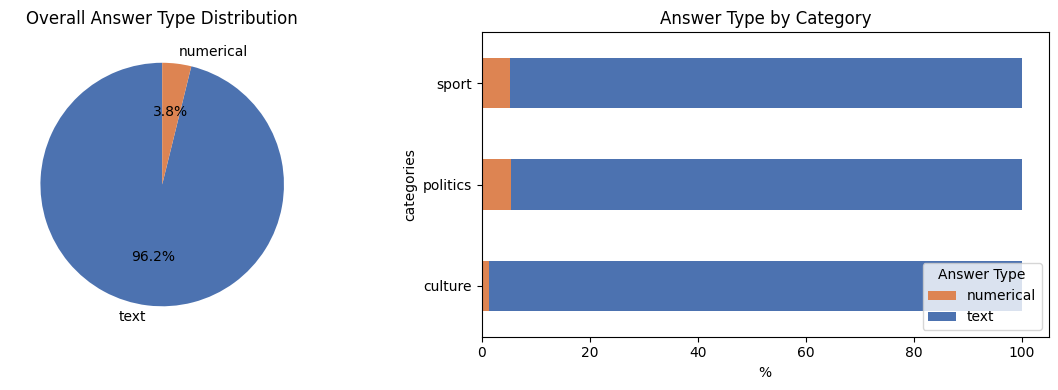

In [10]:
# Pie chart
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].pie(type_counts.values, labels=type_counts.index, autopct="%1.1f%%",
            startangle=90, colors=["#4C72B0", "#DD8452"])
axes[0].set_title("Overall Answer Type Distribution")

# By category stacked bar
ct_pct.plot.barh(stacked=True, ax=axes[1], color=["#DD8452", "#4C72B0"])
axes[1].set_xlabel("%")
axes[1].set_title("Answer Type by Category")
axes[1].legend(title="Answer Type", loc="lower right")

plt.tight_layout()
plt.show()

In [11]:
def normalise(text: str) -> str:
    text = str(text).lower().strip()
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    return " ".join(text.split())


def _as_list(val):
    if isinstance(val, (list, np.ndarray)):
        return [str(v) for v in val]
    s = str(val).strip()
    if s.startswith("["):
        try:
            p = ast.literal_eval(s)
            return [str(v) for v in p] if isinstance(p, list) else [s]
        except (ValueError, SyntaxError):
            pass
    return [s]


def exact_match(pred: str, truth) -> float:
    pred = normalise(pred)
    return 1.0 if any(normalise(t) == pred for t in _as_list(truth)) else 0.0


def token_f1(pred: str, truth) -> float:
    pred_tokens = normalise(pred).split()
    truths = _as_list(truth)
    if not pred_tokens:
        return 0.0
    best = 0.0
    for t in truths:
        tt = normalise(t).split()
        if not tt:
            continue
        common = Counter(pred_tokens) & Counter(tt)
        n = sum(common.values())
        if n == 0:
            continue
        prec = n / len(pred_tokens)
        rec = n / len(tt)
        best = max(best, 2 * prec * rec / (prec + rec))
    return best


def contains_match(pred: str, truth) -> float:
    pred = normalise(pred)
    return 1.0 if any(normalise(t) in pred for t in _as_list(truth)) else 0.0


print("Scoring functions defined.")

Scoring functions defined.


In [12]:
# Discover all run_04 vllm parquet files (exclude base-pretrained with small row counts)
parquet_files = sorted(BENCHMARK_DIR.glob(f"benchmark_*_{RUN_TAG}.parquet"))
parquet_files = [f for f in parquet_files if "scored" not in f.name]

ANSWER_COLS = ["answer", "model_answer_invariant", "model_answer_relative", "model_answer_explicit"]

print(f"Found {len(parquet_files)} benchmark parquet files:")
for f in parquet_files:
    print(f"  {f.name} ({f.stat().st_size / 1e6:.0f} MB)")

Found 16 benchmark parquet files:
  benchmark_Qwen_Qwen2.5-32B-Instruct_vllm_run_04.parquet (882 MB)
  benchmark_Qwen_Qwen2.5-7B-Instruct_vllm_run_04.parquet (881 MB)
  benchmark_Qwen_Qwen3.5-27B_vllm_run_04.parquet (881 MB)
  benchmark_Qwen_Qwen3.5-4B_vllm_run_04.parquet (880 MB)
  benchmark_claude-haiku-4-5_closed_run_04.parquet (891 MB)
  benchmark_google_gemma-2-27b-it_vllm_run_04.parquet (881 MB)
  benchmark_google_gemma-2-2b-it_vllm_run_04.parquet (880 MB)
  benchmark_google_gemma-3-27b-it_vllm_run_04.parquet (882 MB)
  benchmark_google_gemma-3-4b-it_vllm_run_04.parquet (881 MB)
  benchmark_gpt-5_4-2026-03-05_closed_run_04.parquet (885 MB)
  benchmark_meta-llama_Llama-2-13b-hf_vllm_run_04.parquet (881 MB)
  benchmark_meta-llama_Llama-2-7b-hf_vllm_run_04.parquet (879 MB)
  benchmark_meta-llama_Llama-3.2-3B-Instruct_vllm_run_04.parquet (881 MB)
  benchmark_mistralai_Ministral-3-14B-Instruct-2512-BF16_vllm_run_04.parquet (882 MB)
  benchmark_mistralai_Ministral-3-8B-Instruct-2512-BF

In [13]:
summary_files = sorted(BENCHMARK_DIR.glob(f"benchmark_summary_*_{RUN_TAG}.json"))
print(f"Found {len(summary_files)} summary files for run tag '{RUN_TAG}'")

summaries = []
for f in summary_files:
    with open(f) as fh:
        d = json.load(fh)
    summaries.append(d)

df_summary = pd.DataFrame(summaries)

# Filter to consistent runs (same dataset size)
# df_summary = df_summary[df_summary["dataset_rows"] >= MIN_DATASET_ROWS].reset_index(drop=True)
# print(f"Keeping {len(df_summary)} models with >= {MIN_DATASET_ROWS:,} rows")

# Short model names for display (strip -2512-BF16 from Mistral/Ministral)
df_summary["model_short"] = df_summary["model"].apply(
    lambda m: strip_2512_bf16(m.split("/")[-1])
)
df_summary = df_summary.sort_values("explicit_em", ascending=False).reset_index(drop=True)
df_summary[["model_short", "dataset_rows", "invariant_em", "invariant_f1", "invariant_contains",
            "relative_em", "relative_f1", "relative_contains",
            "explicit_em", "explicit_f1", "explicit_contains",
            "total_wall_time_min"]]

Found 16 summary files for run tag 'run_04'


,model_short,dataset_rows,invariant_em,invariant_f1,invariant_contains,relative_em,relative_f1,relative_contains,explicit_em,explicit_f1,explicit_contains,total_wall_time_min
0,gemma-2-27b-it,359009,0.0574,0.0858,0.0691,0.0536,0.0794,0.0639,0.1371,0.1755,0.1533,50.94
1,gemma-3-27b-it,359009,0.0455,0.0725,0.0591,0.0445,0.0718,0.0579,0.1052,0.1458,0.1277,24.02
2,Llama-2-13b-hf,359009,0.0528,0.0786,0.0598,0.0562,0.0828,0.0644,0.0928,0.1245,0.1042,64.09
3,Qwen3.5-27B,359009,0.0271,0.0398,0.0324,0.0420,0.0658,0.0504,0.0776,0.1086,0.0895,109.76
4,Ministral-3-14B-Instruct,359009,0.0411,0.0668,0.0564,0.0375,0.0623,0.0512,0.0772,0.1079,0.0921,19.55
5,gpt-5.4-2026-03-05,359009,0.0480,0.0770,0.0670,0.0422,0.0715,0.0629,0.0757,0.1042,0.0988,266.79
6,Llama-2-7b-hf,359009,0.0382,0.0550,0.0430,0.0331,0.0472,0.0384,0.0603,0.0785,0.0665,92.21
7,claude-haiku-4-5,359009,0.0045,0.0137,0.0156,0.0075,0.0219,0.0209,0.0559,0.0836,0.0761,37.69
8,Ministral-3-8B-Instruct,359009,0.0345,0.0547,0.0427,0.0324,0.0524,0.0401,0.0540,0.0770,0.0623,33.52
9,Qwen2.5-32B-Instruct,359009,0.0283,0.0499,0.0386,0.0271,0.0500,0.0370,0.0532,0.0805,0.0643,33.82


In [14]:
# RELATIVE AND INVARIANT CALCULATIONS (alternative aggregation)
# For each parquet/model file:
# 1) score each row for relative/invariant prompts (cm, em, f1)
# 2) for each question, take max cm, max em, max f1 across years
# 3) use the event_year from the selected max-cm row
# 4) average those per-question values to one record per file
# Then average those file-level records to produce a final table.

if "CM_F1_MERGE_KEYS" not in globals():
    raise RuntimeError("Run the df_base setup/alignment cells first; CM_F1_MERGE_KEYS is required.")

if "parquet_files" not in globals() or not parquet_files:
    raise RuntimeError("Run the parquet discovery cell first; parquet_files is required.")

base_keys = list(dict.fromkeys(CM_F1_MERGE_KEYS + ["question", "event_year"]))
df_base_keys = df_base[base_keys].drop_duplicates(subset=CM_F1_MERGE_KEYS)

prompt_specs = {
    "relative": "model_answer_relative",
    "invariant": "model_answer_invariant",
}

alt_file_records = []

for pf in parquet_files:
    read_cols = list(dict.fromkeys(ANSWER_COLS + ["model_name"] + CM_F1_MERGE_KEYS))
    df_m = pd.read_parquet(pf, columns=read_cols)

    if len(df_m) < MIN_DATASET_ROWS:
        continue

    model_name_raw = str(df_m["model_name"].iloc[0]).split("/")[-1]
    model_clean = strip_2512_bf16(model_name_raw)

    for prompt_type, pred_col in prompt_specs.items():
        preds = df_m[pred_col].fillna("").astype(str)
        answers = df_m["answer"]

        scores = df_m[CM_F1_MERGE_KEYS].copy()
        scores["cm"] = [contains_match(p, t) for p, t in zip(preds, answers)]
        scores["em"] = [exact_match(p, t) for p, t in zip(preds, answers)]
        scores["f1"] = [token_f1(p, t) for p, t in zip(preds, answers)]

        scores = scores.drop_duplicates(subset=CM_F1_MERGE_KEYS, keep="first")

        scored = df_base_keys.merge(scores, on=CM_F1_MERGE_KEYS, how="left")
        scored = scored.dropna(subset=["cm", "em", "f1", "question", "event_year"])

        if scored.empty:
            continue

        # Select one row per question using max CM (for both cm and its event_year)
        cm_pick_idx = scored.groupby("question")["cm"].idxmax()
        cm_picks = (
            scored.sort_values(["question", "cm", "event_year"], ascending=[True, False, False])
            .drop_duplicates(subset=["question"], keep="first")
            .loc[:, ["question", "event_year", "cm"]]
        )

        q_max = scored.groupby("question", as_index=False).agg(
            em=("em", "max"),
            f1=("f1", "max"),
        )

        alt_file_records.append(
            {
                "parquet_file": pf.name,
                "model_short": model_clean,
                "prompt_type": prompt_type,
                "avg_event_year": cm_picks.loc[cm_picks["cm"] > 0, "event_year"].mean(),
           
                "avg_cm": cm_picks["cm"].mean(),
                "avg_em": q_max["em"].mean(),
                "avg_f1": q_max["f1"].mean(),
                "question_count": cm_picks["question"].nunique(),
            }
        )

alt_file_df = pd.DataFrame(alt_file_records)

# if alt_file_df.empty:
#     raise RuntimeError("No alternative aggregation records were produced.")

# alt_prompt_summary = (
#     alt_file_df
#     .groupby("prompt_type", as_index=False)
#     .agg(
#         average_year=("avg_event_year", "mean"),
#         average_cm=("avg_cm", "mean"),
#         average_em=("avg_em", "mean"),
#         average_f1=("avg_f1", "mean"),
#         n_parquet_files=("parquet_file", "nunique"),
#     )
#     .sort_values("prompt_type")
# )




In [17]:
alt_prompt_summary = (
    alt_file_df
    .groupby(["model_short", "prompt_type"], as_index=False)
    .agg(
        average_year=("avg_event_year", "mean"),
        average_cm=("avg_cm", "mean"),
        average_em=("avg_em", "mean"),
        average_f1=("avg_f1", "mean"),
        n_parquet_files=("parquet_file", "nunique"),
    )
    .sort_values(["model_short", "prompt_type"])
)
alt_prompt_summary

,model_short,prompt_type,average_year,average_cm,average_em,average_f1,n_parquet_files
0,Llama-2-13b-hf,invariant,2018.711715,0.292094,0.248958,0.331011,1
1,Llama-2-13b-hf,relative,2019.000688,0.316163,0.266140,0.350475,1
2,Llama-2-7b-hf,invariant,2019.171645,0.191757,0.170805,0.219689,1
3,Llama-2-7b-hf,relative,2019.474429,0.158770,0.136622,0.173829,1
4,Llama-3.2-3B-Instruct,invariant,2019.670111,0.147352,0.117845,0.170265,1
5,Llama-3.2-3B-Instruct,relative,2020.460294,0.120963,0.091347,0.136783,1
6,Ministral-3-14B-Instruct,invariant,2020.113897,0.274658,0.181281,0.280411,1
7,Ministral-3-14B-Instruct,relative,2020.673950,0.257150,0.174974,0.268336,1
8,Ministral-3-8B-Instruct,invariant,2019.993043,0.213615,0.166020,0.245863,1
9,Ministral-3-8B-Instruct,relative,2020.430168,0.207634,0.163338,0.243458,1


In [23]:
%%time

# Compute per-row EM, F1, CM scores for each model across all three prompt types
# (explicit, relative, invariant).
# Produces a DataFrame unique by (question, event_year, model_name) with columns:
#   explicit_em, explicit_f1, explicit_cm,
#   relative_em, relative_f1, relative_cm,
#   invariant_em, invariant_f1, invariant_cm

score_rows = []
n_rows = None

for pf in parquet_files:
    print(f"Processing {pf.name} ...", end=" ")
    df_m = pd.read_parquet(
        pf, columns=ANSWER_COLS + ["model_name", "question", "event_year"]
    )
    # Keep only unique (question, event_year, model_name) combinations
    df_m = df_m.drop_duplicates(subset=["question", "event_year", "model_name"])

    if len(df_m) < MIN_DATASET_ROWS:
        print(f"skipped ({len(df_m):,} rows < {MIN_DATASET_ROWS:,})")
        continue

    if n_rows is None:
        n_rows = len(df_m)
        answers = df_m["answer"].copy()

    model_short = strip_2512_bf16(df_m["model_name"].iloc[0].split("/")[-1])

    answers_list = df_m["answer"].tolist()
    questions_list = df_m["question"].tolist()
    years_list = df_m["event_year"].tolist()

    # Compute EM, F1, CM for all three prompt types
    variant_scores = {}
    for variant in ["explicit", "relative", "invariant"]:
        col = f"model_answer_{variant}"
        preds = df_m[col].fillna("").astype(str).tolist()
        em = [exact_match(p, t) for p, t in zip(preds, answers_list)]
        f1 = [token_f1(p, t) for p, t in zip(preds, answers_list)]
        cm = [contains_match(p, t) for p, t in zip(preds, answers_list)]
        variant_scores[variant] = {"em": em, "f1": f1, "cm": cm}

    for idx in range(len(questions_list)):
        row = {
            "model_name": model_short,
            "question": questions_list[idx],
            "event_year": years_list[idx],
        }
        for variant in ["explicit", "relative", "invariant"]:
            row[f"{variant}_em"] = variant_scores[variant]["em"][idx]
            row[f"{variant}_f1"] = variant_scores[variant]["f1"][idx]
            row[f"{variant}_cm"] = variant_scores[variant]["cm"][idx]
        score_rows.append(row)

    exp = variant_scores["explicit"]
    rel = variant_scores["relative"]
    inv = variant_scores["invariant"]
    print(
        f"{model_short}: "
        f"expl(EM={np.mean(exp['em']):.4f}, F1={np.mean(exp['f1']):.4f}, CM={np.mean(exp['cm']):.4f}) "
        f"rel(EM={np.mean(rel['em']):.4f}, F1={np.mean(rel['f1']):.4f}, CM={np.mean(rel['cm']):.4f}) "
        f"inv(EM={np.mean(inv['em']):.4f}, F1={np.mean(inv['f1']):.4f}, CM={np.mean(inv['cm']):.4f})"
    )
    del df_m

# Build a DataFrame unique by (question, event_year, model_name)
scores_df = pd.DataFrame(score_rows)
print(
    f"\nProcessed {scores_df['model_name'].nunique()} models, "
    f"{len(scores_df):,} scored rows total (unique by question, event_year, model_name)."
)
print(f"Score columns: {[c for c in scores_df.columns if c.endswith(('_em', '_f1', '_cm'))]}")

Processing benchmark_Qwen_Qwen2.5-32B-Instruct_vllm_run_04.parquet ... Qwen2.5-32B-Instruct: expl(EM=0.0562, F1=0.0863, CM=0.0760) rel(EM=0.0286, F1=0.0534, CM=0.0427) inv(EM=0.0298, F1=0.0529, CM=0.0443)
Processing benchmark_Qwen_Qwen2.5-7B-Instruct_vllm_run_04.parquet ... Qwen2.5-7B-Instruct: expl(EM=0.0380, F1=0.0610, CM=0.0501) rel(EM=0.0261, F1=0.0446, CM=0.0354) inv(EM=0.0282, F1=0.0469, CM=0.0375)
Processing benchmark_Qwen_Qwen3.5-27B_vllm_run_04.parquet ... Qwen3.5-27B: expl(EM=0.0811, F1=0.1144, CM=0.1042) rel(EM=0.0441, F1=0.0696, CM=0.0575) inv(EM=0.0280, F1=0.0412, CM=0.0349)
Processing benchmark_Qwen_Qwen3.5-4B_vllm_run_04.parquet ... Qwen3.5-4B: expl(EM=0.0396, F1=0.0640, CM=0.0493) rel(EM=0.0276, F1=0.0464, CM=0.0333) inv(EM=0.0268, F1=0.0448, CM=0.0331)
Processing benchmark_claude-haiku-4-5_closed_run_04.parquet ... claude-haiku-4-5: expl(EM=0.0583, F1=0.0867, CM=0.0819) rel(EM=0.0079, F1=0.0228, CM=0.0223) inv(EM=0.0047, F1=0.0144, CM=0.0169)
Processing benchmark_googl

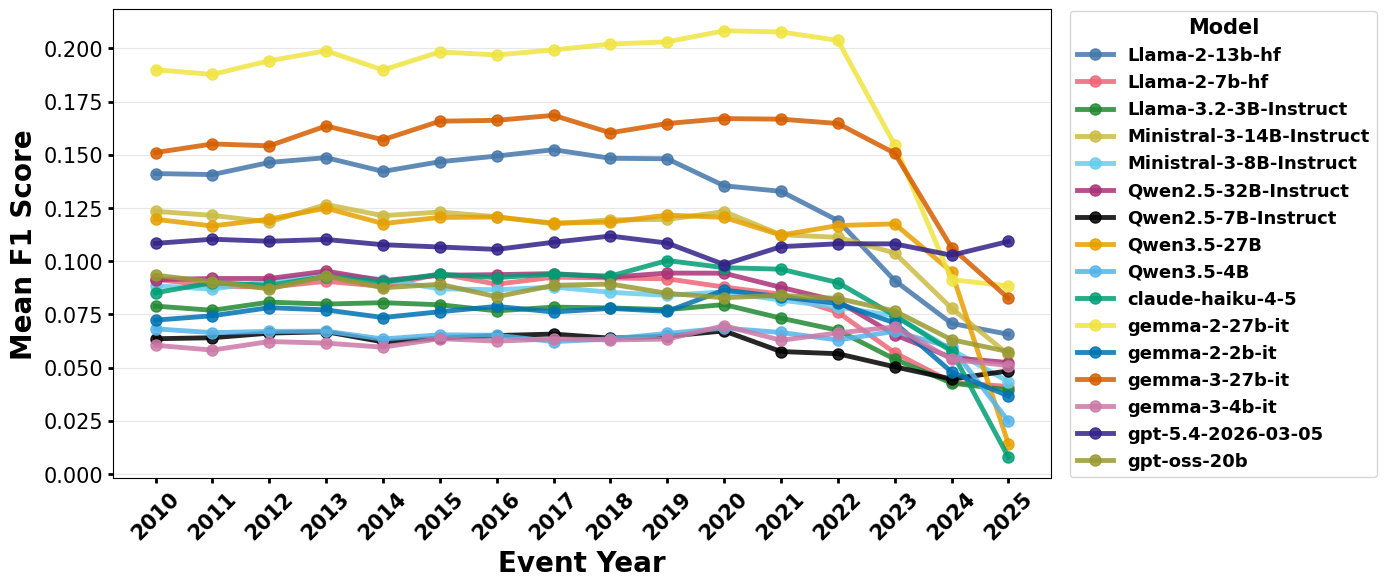

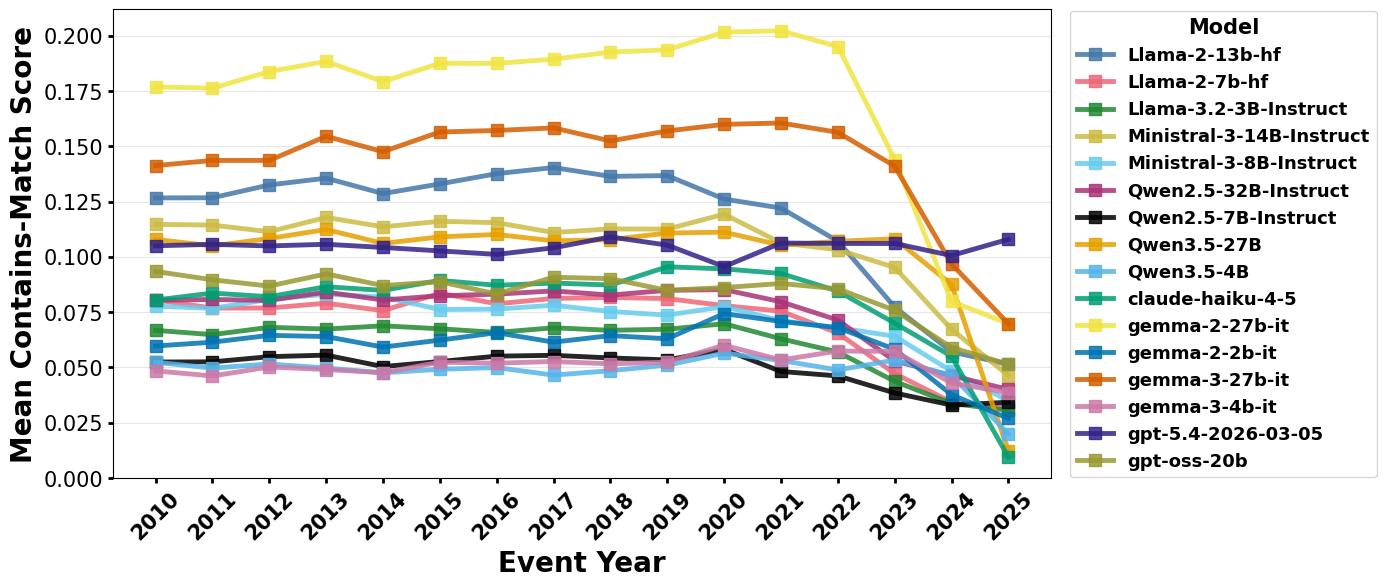


Year range: 2010.0 – 2025.0

Per-model F1 range (across all years):
  Llama-2-13b-hf                                 min=0.0657  max=0.1524
  Llama-2-7b-hf                                  min=0.0411  max=0.0941
  Llama-3.2-3B-Instruct                          min=0.0396  max=0.0808
  Ministral-3-14B-Instruct                       min=0.0562  max=0.1266
  Ministral-3-8B-Instruct                        min=0.0434  max=0.0940
  Qwen2.5-32B-Instruct                           min=0.0524  max=0.0953
  Qwen2.5-7B-Instruct                            min=0.0446  max=0.0673
  Qwen3.5-27B                                    min=0.0141  max=0.1249
  Qwen3.5-4B                                     min=0.0248  max=0.0686
  claude-haiku-4-5                               min=0.0079  max=0.1003
  gemma-2-27b-it                                 min=0.0884  max=0.2083
  gemma-2-2b-it                                  min=0.0366  max=0.0864
  gemma-3-27b-it                                 min=0.0826  max=0.

In [24]:
# F1 scores over the years, split by model (explicit prompt only)
# Build a temporary DataFrame with per-model F1 and event_year

# Helper function to clean model names for display
def _clean_model_name(m):
    m_clean = strip_2512_bf16(m)  # Remove -2512-BF16 from Mistral/Ministral
    if "/" in m_clean:
        m_clean = m_clean.split("/")[-1]
    if m_clean.endswith(".pth"):
        m_clean = m_clean[:-4]
    m_clean = m_clean.strip(" -_")
    return m_clean

# Use scores_df with explicit variant columns
_plot_df = scores_df.copy()
_plot_df["model_clean"] = _plot_df["model_name"].map(_clean_model_name)
_model_names = sorted(_plot_df["model_name"].unique())
_cleaned_model_names = [_clean_model_name(m) for m in _model_names]

# Build yearly mean tables from explicit scores
_yearly_f1 = (
    _plot_df.groupby(["event_year", "model_clean"], as_index=False)["explicit_f1"]
    .mean()
    .pivot(index="event_year", columns="model_clean", values="explicit_f1")
    .sort_index()
)
_yearly_cm = (
    _plot_df.groupby(["event_year", "model_clean"], as_index=False)["explicit_cm"]
    .mean()
    .pivot(index="event_year", columns="model_clean", values="explicit_cm")
    .sort_index()
)

# --- Plot 1: F1 Scores ---
fig_f1, ax_f1 = plt.subplots(figsize=(14, 6))
_model_colors = get_model_color_map(_model_names)
for idx, mc in enumerate(_cleaned_model_names):
    ax_f1.plot(
        _yearly_f1.index, 
        _yearly_f1[mc], 
        marker="o", 
        markersize=8,
        linewidth=3.5,
        color=_model_colors[_model_names[idx]], 
        label=mc, 
        alpha=0.85
    )

ax_f1.set_ylabel(
    "Mean F1 Score", 
    fontsize=20, 
    fontweight="bold"
)
# Title removed

# Set legend to the right of the plot
legend_f1 = ax_f1.legend(
    loc="center left",             
    bbox_to_anchor=(1.02, 0.5),    
    fontsize=13, 
    ncol=1, 
    title="Model", 
    title_fontsize=15, 
    frameon=True,
    borderaxespad=0.0
)
for text in legend_f1.get_texts():
    text.set_fontweight("bold")
if legend_f1.get_title():
    legend_f1.get_title().set_fontweight("bold")

ax_f1.grid(axis="y", alpha=0.3)
ax_f1.set_xlabel(
    "Event Year", 
    fontsize=20, 
    fontweight="bold"
)
ax_f1.set_xticks(_yearly_f1.index)
ax_f1.set_xticklabels(
    [str(int(y)) for y in _yearly_f1.index], 
    rotation=45, 
    fontsize=14, 
    fontweight="bold"
)
ax_f1.tick_params(axis="y", labelsize=15, width=2)
ax_f1.tick_params(axis="x", labelsize=15, width=2)

plt.tight_layout()
plt.show()

# --- Plot 2: Contains-Match Scores ---
fig_cm, ax_cm = plt.subplots(figsize=(14, 6))
for idx, mc in enumerate(_cleaned_model_names):
    ax_cm.plot(
        _yearly_cm.index, 
        _yearly_cm[mc], 
        marker="s", 
        markersize=8,
        linewidth=3.5,
        color=_model_colors[_model_names[idx]], 
        label=mc, 
        alpha=0.85
    )

ax_cm.set_xlabel(
    "Event Year", 
    fontsize=20, 
    fontweight="bold"
)
ax_cm.set_ylabel(
    "Mean Contains-Match Score", 
    fontsize=20, 
    fontweight="bold"
)
# Title removed

legend_cm = ax_cm.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=13, 
    ncol=1, 
    title="Model", 
    title_fontsize=15, 
    frameon=True,
    borderaxespad=0.0
)
for text in legend_cm.get_texts():
    text.set_fontweight("bold")
if legend_cm.get_title():
    legend_cm.get_title().set_fontweight("bold")

ax_cm.grid(axis="y", alpha=0.3)
ax_cm.set_xticks(_yearly_cm.index)
ax_cm.set_xticklabels(
    [str(int(y)) for y in _yearly_cm.index], 
    rotation=45, 
    fontsize=14, 
    fontweight="bold"
)
ax_cm.tick_params(axis="y", labelsize=15, width=2)
ax_cm.tick_params(axis="x", labelsize=15, width=2)

plt.tight_layout()
plt.show()

# Summary stats
print(f"\nYear range: {_yearly_f1.index.min()} – {_yearly_f1.index.max()}")
print(f"\nPer-model F1 range (across all years):")
for mc in _cleaned_model_names:
    print(f"  {mc:45s}  min={_yearly_f1[mc].min():.4f}  max={_yearly_f1[mc].max():.4f}")
print(f"\nPer-model CM range (across all years):")
for mc in _cleaned_model_names:
    print(f"  {mc:45s}  min={_yearly_cm[mc].min():.4f}  max={_yearly_cm[mc].max():.4f}")

del _plot_df, _yearly_f1, _yearly_cm

/scratch/jk87/sg9944/tmp/ipykernel_3188988/2169929342.py:98: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.25, 1, 1])  # Reserve bottom 25% for legend (avoid x-axis overlap)


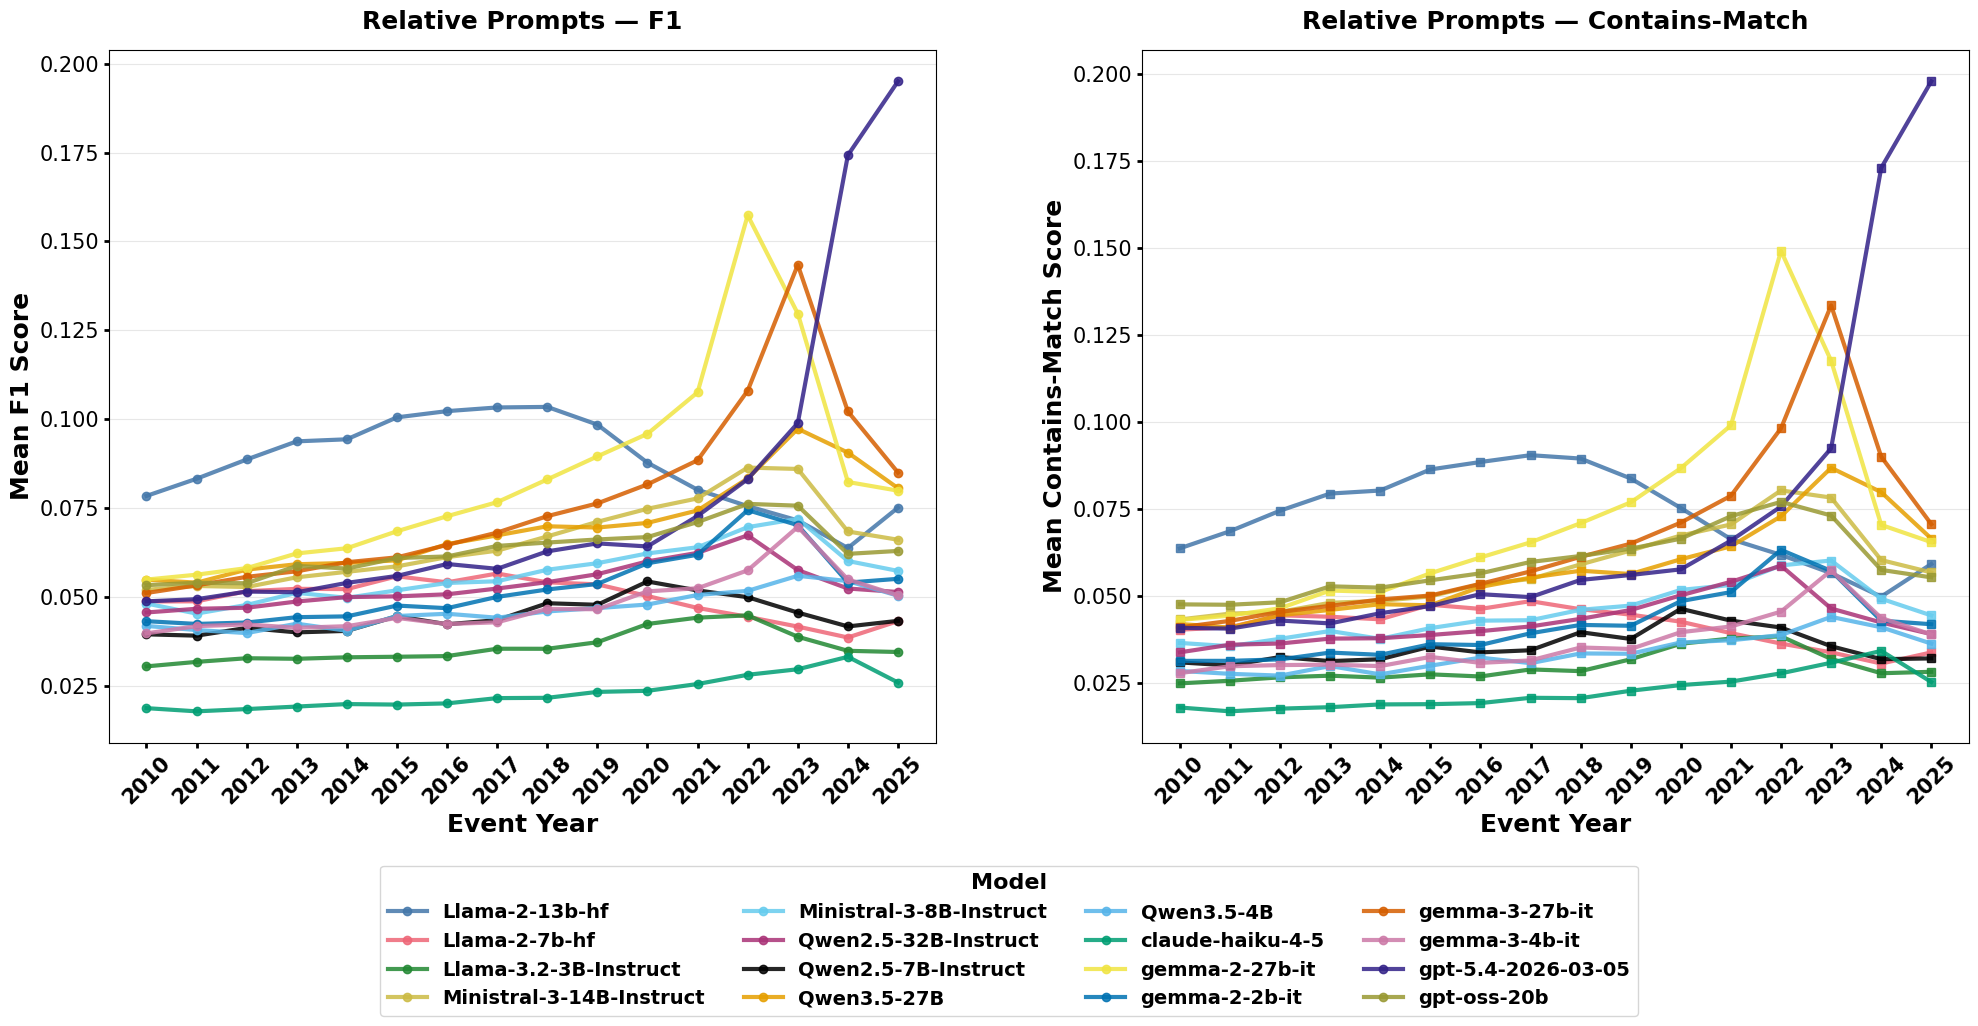

/scratch/jk87/sg9944/tmp/ipykernel_3188988/2169929342.py:154: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.25, 1, 1])  # Reserve bottom 25% for legend (avoid x-axis overlap)


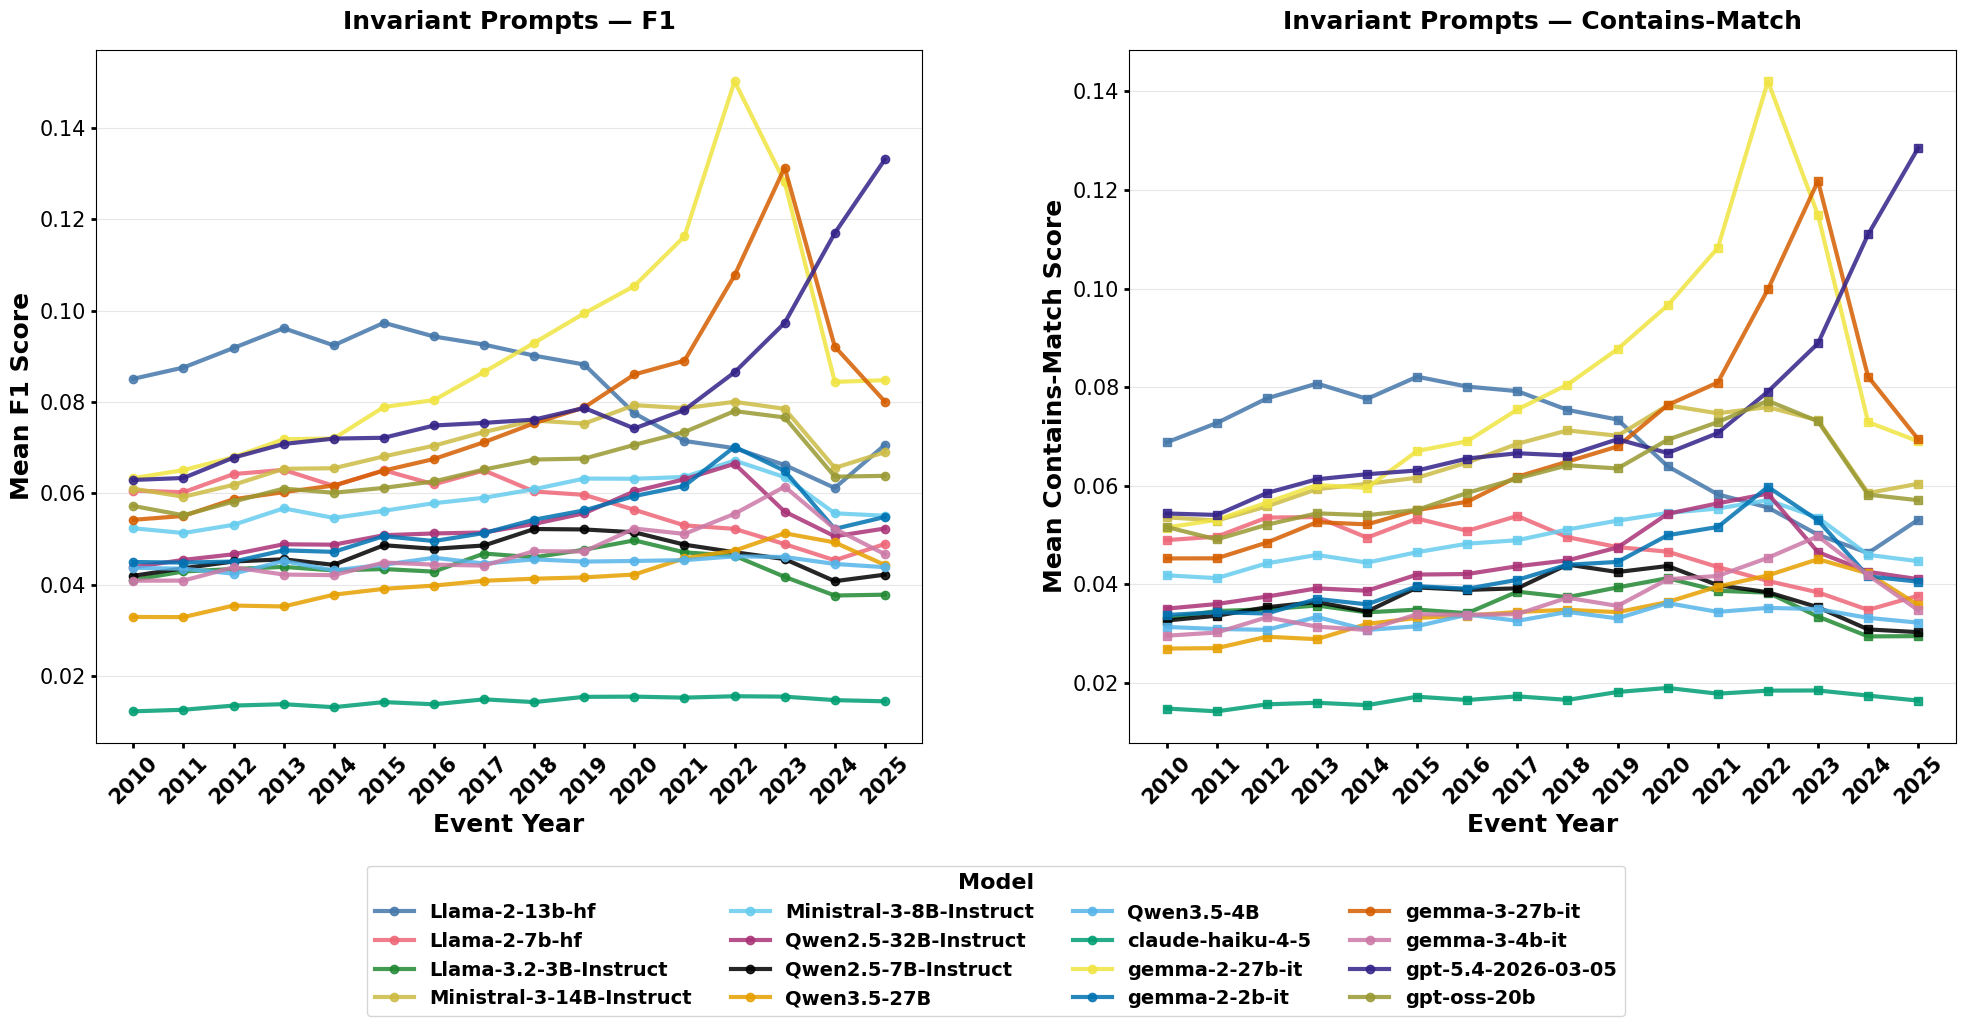


=== RELATIVE PROMPT ===
Year range: 2010.0 – 2025.0
Per-model F1 range:
  Llama-2-13b-hf                                 min=0.0637  max=0.1034
  Llama-2-7b-hf                                  min=0.0385  max=0.0565
  Llama-3.2-3B-Instruct                          min=0.0304  max=0.0448
  Ministral-3-14B-Instruct                       min=0.0520  max=0.0864
  Ministral-3-8B-Instruct                        min=0.0453  max=0.0719
  Qwen2.5-32B-Instruct                           min=0.0456  max=0.0673
  Qwen2.5-7B-Instruct                            min=0.0390  max=0.0543
  Qwen3.5-27B                                    min=0.0540  max=0.0973
  Qwen3.5-4B                                     min=0.0398  max=0.0559
  claude-haiku-4-5                               min=0.0177  max=0.0331
  gemma-2-27b-it                                 min=0.0548  max=0.1574
  gemma-2-2b-it                                  min=0.0423  max=0.0744
  gemma-3-27b-it                                 min=0.0511  ma

In [25]:
# Plot relative and invariant F1/CM scores over the years using scores_df
# (scores_df already has relative_f1, relative_cm, invariant_f1, invariant_cm from the scoring cell)

_plot_df = scores_df.copy()
_plot_df["model_clean"] = _plot_df["model_name"].map(_clean_model_name)
_model_names = sorted(_plot_df["model_name"].unique())

# --- Relative prompt yearly means ---
_yearly_f1_rel = (
    _plot_df.groupby(["event_year", "model_name"], as_index=False)["relative_f1"]
    .mean()
    .pivot(index="event_year", columns="model_name", values="relative_f1")
    .sort_index()
)
_yearly_cm_rel = (
    _plot_df.groupby(["event_year", "model_name"], as_index=False)["relative_cm"]
    .mean()
    .pivot(index="event_year", columns="model_name", values="relative_cm")
    .sort_index()
)

# --- Invariant prompt yearly means ---
_yearly_f1_inv = (
    _plot_df.groupby(["event_year", "model_name"], as_index=False)["invariant_f1"]
    .mean()
    .pivot(index="event_year", columns="model_name", values="invariant_f1")
    .sort_index()
)
_yearly_cm_inv = (
    _plot_df.groupby(["event_year", "model_name"], as_index=False)["invariant_cm"]
    .mean()
    .pivot(index="event_year", columns="model_name", values="invariant_cm")
    .sort_index()
)

_model_colors = get_model_color_map(_model_names)

# Style settings
LABEL_FONTSIZE = 18
TICK_FONTSIZE = 15
LEGEND_FONTSIZE = 14
LEGEND_TITLE_FONTSIZE = 16
LINE_WIDTH = 3
AXIS_WEIGHT = 2  # for tick lines

# ======= RELATIVE: F1 + CM (side by side, bigger plot, increased legend space) =======
fig_rel, (ax_f1_rel, ax_cm_rel) = plt.subplots(
    1, 2, figsize=(24, 9), sharey=False, gridspec_kw={'wspace': 0.25}
)

# F1 for RELATIVE
for idx, m in enumerate(_model_names):
    ax_f1_rel.plot(
        _yearly_f1_rel.index, _yearly_f1_rel[m], marker="o", markersize=6,
        linewidth=LINE_WIDTH, color=_model_colors[m], label=m, alpha=0.85
    )
ax_f1_rel.set_xlabel("Event Year", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax_f1_rel.set_ylabel("Mean F1 Score", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax_f1_rel.set_title("Relative Prompts — F1", fontsize=LABEL_FONTSIZE, fontweight="bold", pad=15)
ax_f1_rel.grid(axis="y", alpha=0.3)
ax_f1_rel.set_xticks(_yearly_f1_rel.index)
ax_f1_rel.set_xticklabels([str(int(y)) for y in _yearly_f1_rel.index], rotation=45, fontsize=TICK_FONTSIZE, fontweight="bold")
ax_f1_rel.tick_params(axis="y", labelsize=TICK_FONTSIZE, width=AXIS_WEIGHT)
ax_f1_rel.tick_params(axis="x", labelsize=TICK_FONTSIZE, width=AXIS_WEIGHT)

# CM for RELATIVE
for idx, m in enumerate(_model_names):
    ax_cm_rel.plot(
        _yearly_cm_rel.index, _yearly_cm_rel[m], marker="s", markersize=6,
        linewidth=LINE_WIDTH, color=_model_colors[m], label=m, alpha=0.85
    )
ax_cm_rel.set_xlabel("Event Year", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax_cm_rel.set_ylabel("Mean Contains-Match Score", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax_cm_rel.set_title("Relative Prompts — Contains-Match", fontsize=LABEL_FONTSIZE, fontweight="bold", pad=15)
ax_cm_rel.grid(axis="y", alpha=0.3)
ax_cm_rel.set_xticks(_yearly_cm_rel.index)
ax_cm_rel.set_xticklabels([str(int(y)) for y in _yearly_cm_rel.index], rotation=45, fontsize=TICK_FONTSIZE, fontweight="bold")
ax_cm_rel.tick_params(axis="y", labelsize=TICK_FONTSIZE, width=AXIS_WEIGHT)
ax_cm_rel.tick_params(axis="x", labelsize=TICK_FONTSIZE, width=AXIS_WEIGHT)

# Place legend beneath both subplots (more space for legend)
handles, labels = ax_f1_rel.get_legend_handles_labels()
legend_rel = fig_rel.legend(
    handles, labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.2),
    fontsize=LEGEND_FONTSIZE,
    ncol=min(4, len(_model_names)),
    title="Model",
    title_fontsize=LEGEND_TITLE_FONTSIZE,
    frameon=True,
    borderaxespad=0.3,
)
for text in legend_rel.get_texts():
    text.set_fontweight("bold")
if legend_rel.get_title():
    legend_rel.get_title().set_fontweight("bold")
plt.tight_layout(rect=[0, 0.25, 1, 1])  # Reserve bottom 25% for legend (avoid x-axis overlap)
plt.show()


# ======= INVARIANT: F1 + CM (side by side, bigger plot, increased legend space) =======
fig_inv, (ax_f1_inv, ax_cm_inv) = plt.subplots(
    1, 2, figsize=(24, 9), sharey=False, gridspec_kw={'wspace': 0.25}
)

# F1 for INVARIANT
for idx, m in enumerate(_model_names):
    ax_f1_inv.plot(
        _yearly_f1_inv.index, _yearly_f1_inv[m], marker="o", markersize=6,
        linewidth=LINE_WIDTH, color=_model_colors[m], label=m, alpha=0.85
    )
ax_f1_inv.set_xlabel("Event Year", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax_f1_inv.set_ylabel("Mean F1 Score", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax_f1_inv.set_title("Invariant Prompts — F1", fontsize=LABEL_FONTSIZE, fontweight="bold", pad=15)
ax_f1_inv.grid(axis="y", alpha=0.3)
ax_f1_inv.set_xticks(_yearly_f1_inv.index)
ax_f1_inv.set_xticklabels([str(int(y)) for y in _yearly_f1_inv.index], rotation=45, fontsize=TICK_FONTSIZE, fontweight="bold")
ax_f1_inv.tick_params(axis="y", labelsize=TICK_FONTSIZE, width=AXIS_WEIGHT)
ax_f1_inv.tick_params(axis="x", labelsize=TICK_FONTSIZE, width=AXIS_WEIGHT)

# CM for INVARIANT
for idx, m in enumerate(_model_names):
    ax_cm_inv.plot(
        _yearly_cm_inv.index, _yearly_cm_inv[m], marker="s", markersize=6,
        linewidth=LINE_WIDTH, color=_model_colors[m], label=m, alpha=0.85
    )
ax_cm_inv.set_xlabel("Event Year", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax_cm_inv.set_ylabel("Mean Contains-Match Score", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax_cm_inv.set_title("Invariant Prompts — Contains-Match", fontsize=LABEL_FONTSIZE, fontweight="bold", pad=15)
ax_cm_inv.grid(axis="y", alpha=0.3)
ax_cm_inv.set_xticks(_yearly_cm_inv.index)
ax_cm_inv.set_xticklabels([str(int(y)) for y in _yearly_cm_inv.index], rotation=45, fontsize=TICK_FONTSIZE, fontweight="bold")
ax_cm_inv.tick_params(axis="y", labelsize=TICK_FONTSIZE, width=AXIS_WEIGHT)
ax_cm_inv.tick_params(axis="x", labelsize=TICK_FONTSIZE, width=AXIS_WEIGHT)

# Place legend beneath both subplots (more space for legend)
handles, labels = ax_f1_inv.get_legend_handles_labels()
legend_inv = fig_inv.legend(
    handles, labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.20),
    fontsize=LEGEND_FONTSIZE,
    ncol=min(4, len(_model_names)),
    title="Model",
    title_fontsize=LEGEND_TITLE_FONTSIZE,
    frameon=True,
    borderaxespad=0.3,
)
for text in legend_inv.get_texts():
    text.set_fontweight("bold")
if legend_inv.get_title():
    legend_inv.get_title().set_fontweight("bold")
plt.tight_layout(rect=[0, 0.25, 1, 1])  # Reserve bottom 25% for legend (avoid x-axis overlap)
plt.show()


# Summary
print("\n=== RELATIVE PROMPT ===")
print(f"Year range: {_yearly_f1_rel.index.min()} – {_yearly_f1_rel.index.max()}")
print("Per-model F1 range:")
for m in _model_names:
    print(f"  {m:45s}  min={_yearly_f1_rel[m].min():.4f}  max={_yearly_f1_rel[m].max():.4f}")
print("Per-model CM range:")
for m in _model_names:
    print(f"  {m:45s}  min={_yearly_cm_rel[m].min():.4f}  max={_yearly_cm_rel[m].max():.4f}")

print("\n=== INVARIANT PROMPT ===")
print(f"Year range: {_yearly_f1_inv.index.min()} – {_yearly_f1_inv.index.max()}")
print("Per-model F1 range:")
for m in _model_names:
    print(f"  {m:45s}  min={_yearly_f1_inv[m].min():.4f}  max={_yearly_f1_inv[m].max():.4f}")
print("Per-model CM range:")
for m in _model_names:
    print(f"  {m:45s}  min={_yearly_cm_inv[m].min():.4f}  max={_yearly_cm_inv[m].max():.4f}")

del _plot_df, _yearly_f1_rel, _yearly_cm_rel, _yearly_f1_inv, _yearly_cm_inv


In [ ]:
###

In [ ]:
##
# Build per-question difficulty metrics from scores_df (explicit prompt scores).
# scores_df rows are unique on (question, event_year, model_name) with columns:
#   explicit_em, explicit_f1, explicit_cm, relative_*, invariant_*

df_difficulty = df_base.copy()

_row_key = ["question", "event_year", "model_name"]
_dup_mask = scores_df.duplicated(subset=_row_key, keep=False)
if _dup_mask.any():
    raise ValueError(
        f"scores_df must be unique on {_row_key}; "
        f"found {int(_dup_mask.sum())} rows involved in duplicates."
    )

model_names = sorted(scores_df["model_name"].unique())
n_models = len(model_names)

# Reshape explicit scores to wide format: one cm/em/f1 column per model
_sub = scores_df[["question", "event_year", "model_name", "explicit_cm", "explicit_em", "explicit_f1"]].copy()
_sub = _sub.rename(columns={"explicit_cm": "cm", "explicit_em": "em", "explicit_f1": "f1"})
_sub = _sub.set_index(_row_key)[["cm", "em", "f1"]]
_wide_metrics = _sub.unstack("model_name")
_wide_metrics.columns = [f"{metric}_{model}" for metric, model in _wide_metrics.columns]
_wide = _wide_metrics.reset_index()

for _m in model_names:
    for _pfx in ("cm", "em", "f1"):
        _c = f"{_pfx}_{_m}"
        if _c not in _wide.columns:
            _wide[_c] = np.nan
_col_order = ["question", "event_year"] + [
    f"{_pfx}_{_m}" for _pfx in ("cm", "em", "f1") for _m in model_names
]
_wide = _wide[_col_order]

_merged = df_difficulty.merge(_wide, on=["question", "event_year"], how="left", validate="many_to_one")
if len(_merged) != len(df_difficulty):
    raise ValueError(f"Merge changed row count: {len(_merged)} vs df_difficulty {len(df_difficulty)}")

_cm_cols = [f"cm_{m}" for m in model_names]
_em_cols = [f"em_{m}" for m in model_names]
_f1_cols = [f"f1_{m}" for m in model_names]

cm_matrix = _merged[_cm_cols].to_numpy(dtype=float)
em_matrix = _merged[_em_cols].to_numpy(dtype=float)
f1_matrix = _merged[_f1_cols].to_numpy(dtype=float)

# --- per-row metrics (NaNs = missing model score for that row) ---
df_difficulty["models_correct_cm"] = np.nansum(cm_matrix, axis=1).astype(int)
df_difficulty["models_correct_em"] = np.nansum(em_matrix, axis=1).astype(int)
df_difficulty["avg_f1"] = np.nanmean(f1_matrix, axis=1)
df_difficulty["avg_cm"] = np.nanmean(cm_matrix, axis=1)
df_difficulty["avg_em"] = np.nanmean(em_matrix, axis=1)

# --- grouped-by-question metrics (no temporary wide columns on df_difficulty) ---
_q_groups = df_difficulty.groupby("question", sort=False)

def _models_any_year_correct(sub_idx):
    return int((np.nanmax(cm_matrix[sub_idx], axis=0) > 0).sum())

def _avg_f1_by_question(sub_idx):
    return float(np.nanmean(np.nanmean(f1_matrix[sub_idx], axis=0)))

_q_any_correct = {}
_q_avg_f1 = {}
for _q, _idx in _q_groups.indices.items():
    _idx_arr = np.asarray(_idx)
    _q_any_correct[_q] = _models_any_year_correct(_idx_arr)
    _q_avg_f1[_q] = _avg_f1_by_question(_idx_arr)

df_difficulty["models_any_year_correct"] = df_difficulty["question"].map(_q_any_correct)
df_difficulty["avg_f1_by_question"] = df_difficulty["question"].map(_q_avg_f1)

print(f"Per-question metrics computed across {n_models} models (from scores_df, explicit variant; unique on {_row_key}).")

print("\nmodels_correct_cm distribution (per row - old approach):")
print(df_difficulty["models_correct_cm"].value_counts().sort_index())

print("\nmodels_any_year_correct distribution (grouped by question - new approach):")
print(df_difficulty["models_any_year_correct"].value_counts().sort_index())

print("\navg_f1_by_question summary:")
print(df_difficulty["avg_f1_by_question"].describe())


## Difficulties

This section assigns a three-way difficulty label — **Easy**, **Medium**, or **Hard** — to every question in the dataset.

**Definition (6a — Contains-Match):** for each question, count how many of the *N* evaluated models produced a correct answer (contains-match) for *at least one* event year. A question is labelled:
- **Hard** — no model answered it correctly across any year
- **Medium** — between 1 and N/2 models answered it correctly
- **Easy** — more than N/2 models answered it correctly

The resulting `difficulty` column is attached to `df_base` and used throughout the notebook to stratify performance plots and breakdowns by category, relationship type, and prompt type.

In [26]:
# Build per-question difficulty metrics from scores_df (explicit prompt).
# scores_df columns: model_name, question, event_year,
#   explicit_em, explicit_f1, explicit_cm, relative_*, invariant_*

model_names = sorted(scores_df["model_name"].unique())
n_models = len(model_names)

# Pivot scores_df from long (one row per model) to wide (one row per question+year)
# using explicit scores only for difficulty classification.
_sub = scores_df[["question", "event_year", "model_name",
                   "explicit_cm", "explicit_em", "explicit_f1"]].copy()
_sub = _sub.rename(columns={"explicit_cm": "cm", "explicit_em": "em", "explicit_f1": "f1"})
_sub = _sub.set_index(["question", "event_year", "model_name"])[["cm", "em", "f1"]]
_wide = _sub.unstack("model_name")
_wide.columns = [f"{metric}_{model}" for metric, model in _wide.columns]
_wide = _wide.reset_index()

# Ensure every model has cm_/em_/f1_ columns
for _m in model_names:
    for _pfx in ("cm", "em", "f1"):
        _c = f"{_pfx}_{_m}"
        if _c not in _wide.columns:
            _wide[_c] = np.nan

# Merge onto df_base by (question, event_year)
cm_col_names = [f"cm_{m}" for m in model_names]
em_col_names = [f"em_{m}" for m in model_names]
f1_col_names = [f"f1_{m}" for m in model_names]

_merged = df_base.merge(
    _wide[["question", "event_year"] + cm_col_names + em_col_names + f1_col_names],
    on=["question", "event_year"], how="left"
)

cm_matrix = _merged[cm_col_names].to_numpy(dtype=float)
em_matrix = _merged[em_col_names].to_numpy(dtype=float)
f1_matrix = _merged[f1_col_names].to_numpy(dtype=float)

# --- per-row metrics ---
df_base["models_correct_cm"] = np.nansum(cm_matrix, axis=1).astype(int)
df_base["models_correct_em"] = np.nansum(em_matrix, axis=1).astype(int)
df_base["avg_f1"] = np.nanmean(f1_matrix, axis=1)
df_base["avg_cm"] = np.nanmean(cm_matrix, axis=1)
df_base["avg_em"] = np.nanmean(em_matrix, axis=1)

# --- grouped-by-question metrics ---
# Temporarily add per-model columns for groupby
for c in cm_col_names + f1_col_names:
    df_base[c] = _merged[c].values

q_cm_max = df_base.groupby("question")[cm_col_names].max()
q_cm_max["models_any_year_correct"] = (q_cm_max > 0).sum(axis=1).astype(int)

q_f1_mean = df_base.groupby("question")[f1_col_names].mean()
q_f1_mean["avg_f1_by_question"] = q_f1_mean.mean(axis=1)

df_base["models_any_year_correct"] = df_base["question"].map(
    q_cm_max["models_any_year_correct"]
)
df_base["avg_f1_by_question"] = df_base["question"].map(
    q_f1_mean["avg_f1_by_question"]
)

# Clean up temporary per-model columns
df_base.drop(columns=cm_col_names + f1_col_names, inplace=True)

print(f"Per-question metrics computed across {n_models} models (explicit prompt).")

print(f"\nmodels_correct_cm distribution (per row — old approach):")
print(df_base["models_correct_cm"].value_counts().sort_index())

print(f"\nmodels_any_year_correct distribution (grouped by question — new approach):")
print(df_base["models_any_year_correct"].value_counts().sort_index())

print(f"\navg_f1_by_question summary:")
print(df_base["avg_f1_by_question"].describe())

Per-question metrics computed across 16 models (explicit prompt).

models_correct_cm distribution (per row — old approach):
models_correct_cm
0     226601
1      43048
2      22771
3      15007
4      10935
5       8403
6       6629
7       5269
8       4276
9       3620
10      3015
11      2446
12      2112
13      1730
14      1366
15       955
16       394
Name: count, dtype: int64

models_any_year_correct distribution (grouped by question — new approach):
models_any_year_correct
0     92424
1     37299
2     25880
3     20507
4     17970
5     15508
6     14427
7     13672
8     13007
9     13029
10    13648
11    12903
12    14017
13    14282
14    16009
15    15987
16     8008
Name: count, dtype: int64

avg_f1_by_question summary:
count    358577.000000
mean          0.097764
std           0.133762
min           0.000000
25%           0.008958
50%           0.044643
75%           0.133333
max           0.986746
Name: avg_f1_by_question, dtype: float64


In [27]:
half = n_models / 2

def assign_difficulty(n_correct):
    if n_correct == 0:
        return "Hard"
    elif n_correct <= half:
        return "Medium"
    else:
        return "Easy"

# --- 6a: Contains-Match difficulty (grouped by question, any-year-correct) ---
df_base["difficulty"] = df_base["models_any_year_correct"].apply(assign_difficulty)

diff_counts = df_base["difficulty"].value_counts()
diff_pct = (diff_counts / len(df_base) * 100).round(1)

print(f"=== 6a: Contains-Match Difficulty (any-year-correct, grouped by question) ===")
print(f"    {n_models} models, threshold = {half:.0f}")
print()
for g in ["Easy", "Medium", "Hard"]:
    c = diff_counts.get(g, 0)
    p = diff_pct.get(g, 0)
    print(f"  {g:8s}: {c:>8,} rows ({p}%)")
print(f"\n  Total:   {len(df_base):>8,}")

# --- Save per-question ID + difficulty for re-identification ---
_reg_cols = [
    "question_id", "question", "difficulty",
    "models_any_year_correct", "avg_f1_by_question",
    "categories", "relationship", "answer_type", "id",
]
df_question_registry = (
    df_base.drop_duplicates(subset=["question_id"])[_reg_cols]
    .sort_values("question_id")
    .reset_index(drop=True)
)
df_question_registry.to_parquet(QUESTION_REGISTRY_PATH.with_suffix(".parquet"), index=False)
df_question_registry.to_csv(QUESTION_REGISTRY_PATH.with_suffix(".csv"), index=False)
print(f"\nSaved question registry: {QUESTION_REGISTRY_PATH.with_suffix('.parquet')}")
print(f"Also CSV: {QUESTION_REGISTRY_PATH.with_suffix('.csv')}  ({len(df_question_registry):,} questions)")


=== 6a: Contains-Match Difficulty (any-year-correct, grouped by question) ===
    16 models, threshold = 8

  Easy    :  107,883 rows (30.1%)
  Medium  :  158,270 rows (44.1%)
  Hard    :   92,424 rows (25.8%)

  Total:    358,577

=== 6b: F1-Based Difficulty (avg F1 by question, tercile thresholds) ===
    33rd percentile = 0.0167,  66th percentile = 0.0928

  Easy    :  121,924 rows (34.0%)
  Medium  :  118,722 rows (33.1%)
  Hard    :  117,931 rows (32.9%)

  Total:    358,577

Saved question registry: /g/data/sz65/sg9944/temporal-knowledge/data/question_registry_run_04.parquet
Also CSV: /g/data/sz65/sg9944/temporal-knowledge/data/question_registry_run_04.csv  (27,587 questions)


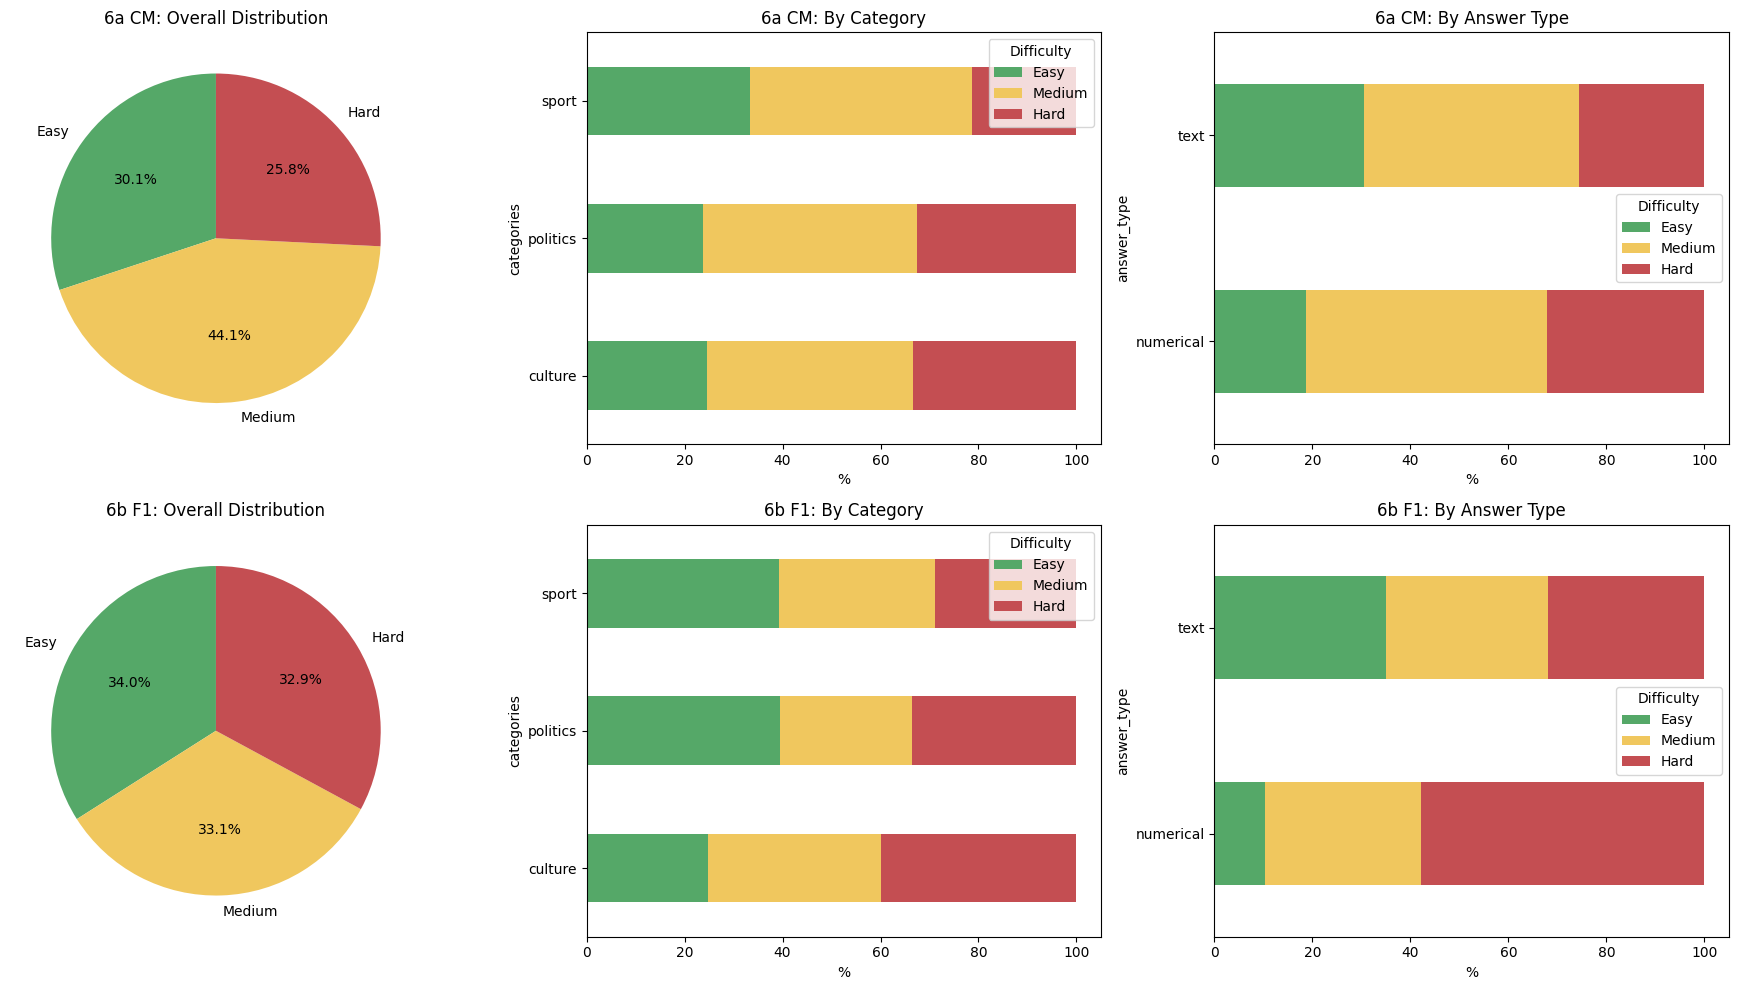

In [28]:
# Difficulty distribution visualization — both definitions
diff_order = ["Easy", "Medium", "Hard"]
colors_diff = {"Easy": "#55A868", "Medium": "#F0C75E", "Hard": "#C44E52"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sizes_cm = [diff_counts.get(g, 0) for g in diff_order]
axes[0].pie(sizes_cm, labels=diff_order, autopct="%1.1f%%", startangle=90,
               colors=[colors_diff[g] for g in diff_order])
axes[0].set_title("6a CM: Overall Distribution")

ct_cat_cm = pd.crosstab(df_base["categories"], df_base["difficulty"], normalize="index") * 100
ct_cat_cm = ct_cat_cm.reindex(columns=diff_order)
ct_cat_cm.plot.barh(stacked=True, ax=axes[1],
                     color=[colors_diff[g] for g in diff_order])
axes[1].set_xlabel("%")
axes[1].set_title("6a CM: By Category")
axes[1].legend(title="Difficulty")

ct_atype_cm = pd.crosstab(df_base["answer_type"], df_base["difficulty"], normalize="index") * 100
ct_atype_cm = ct_atype_cm.reindex(columns=diff_order)
ct_atype_cm.plot.barh(stacked=True, ax=axes[2],
                       color=[colors_diff[g] for g in diff_order])
axes[2].set_xlabel("%")
axes[2].set_title("6a CM: By Answer Type")
axes[2].legend(title="Difficulty")


=== 8a-explicit: Explicit scores by Contains-Match Difficulty (any-year-correct) ===



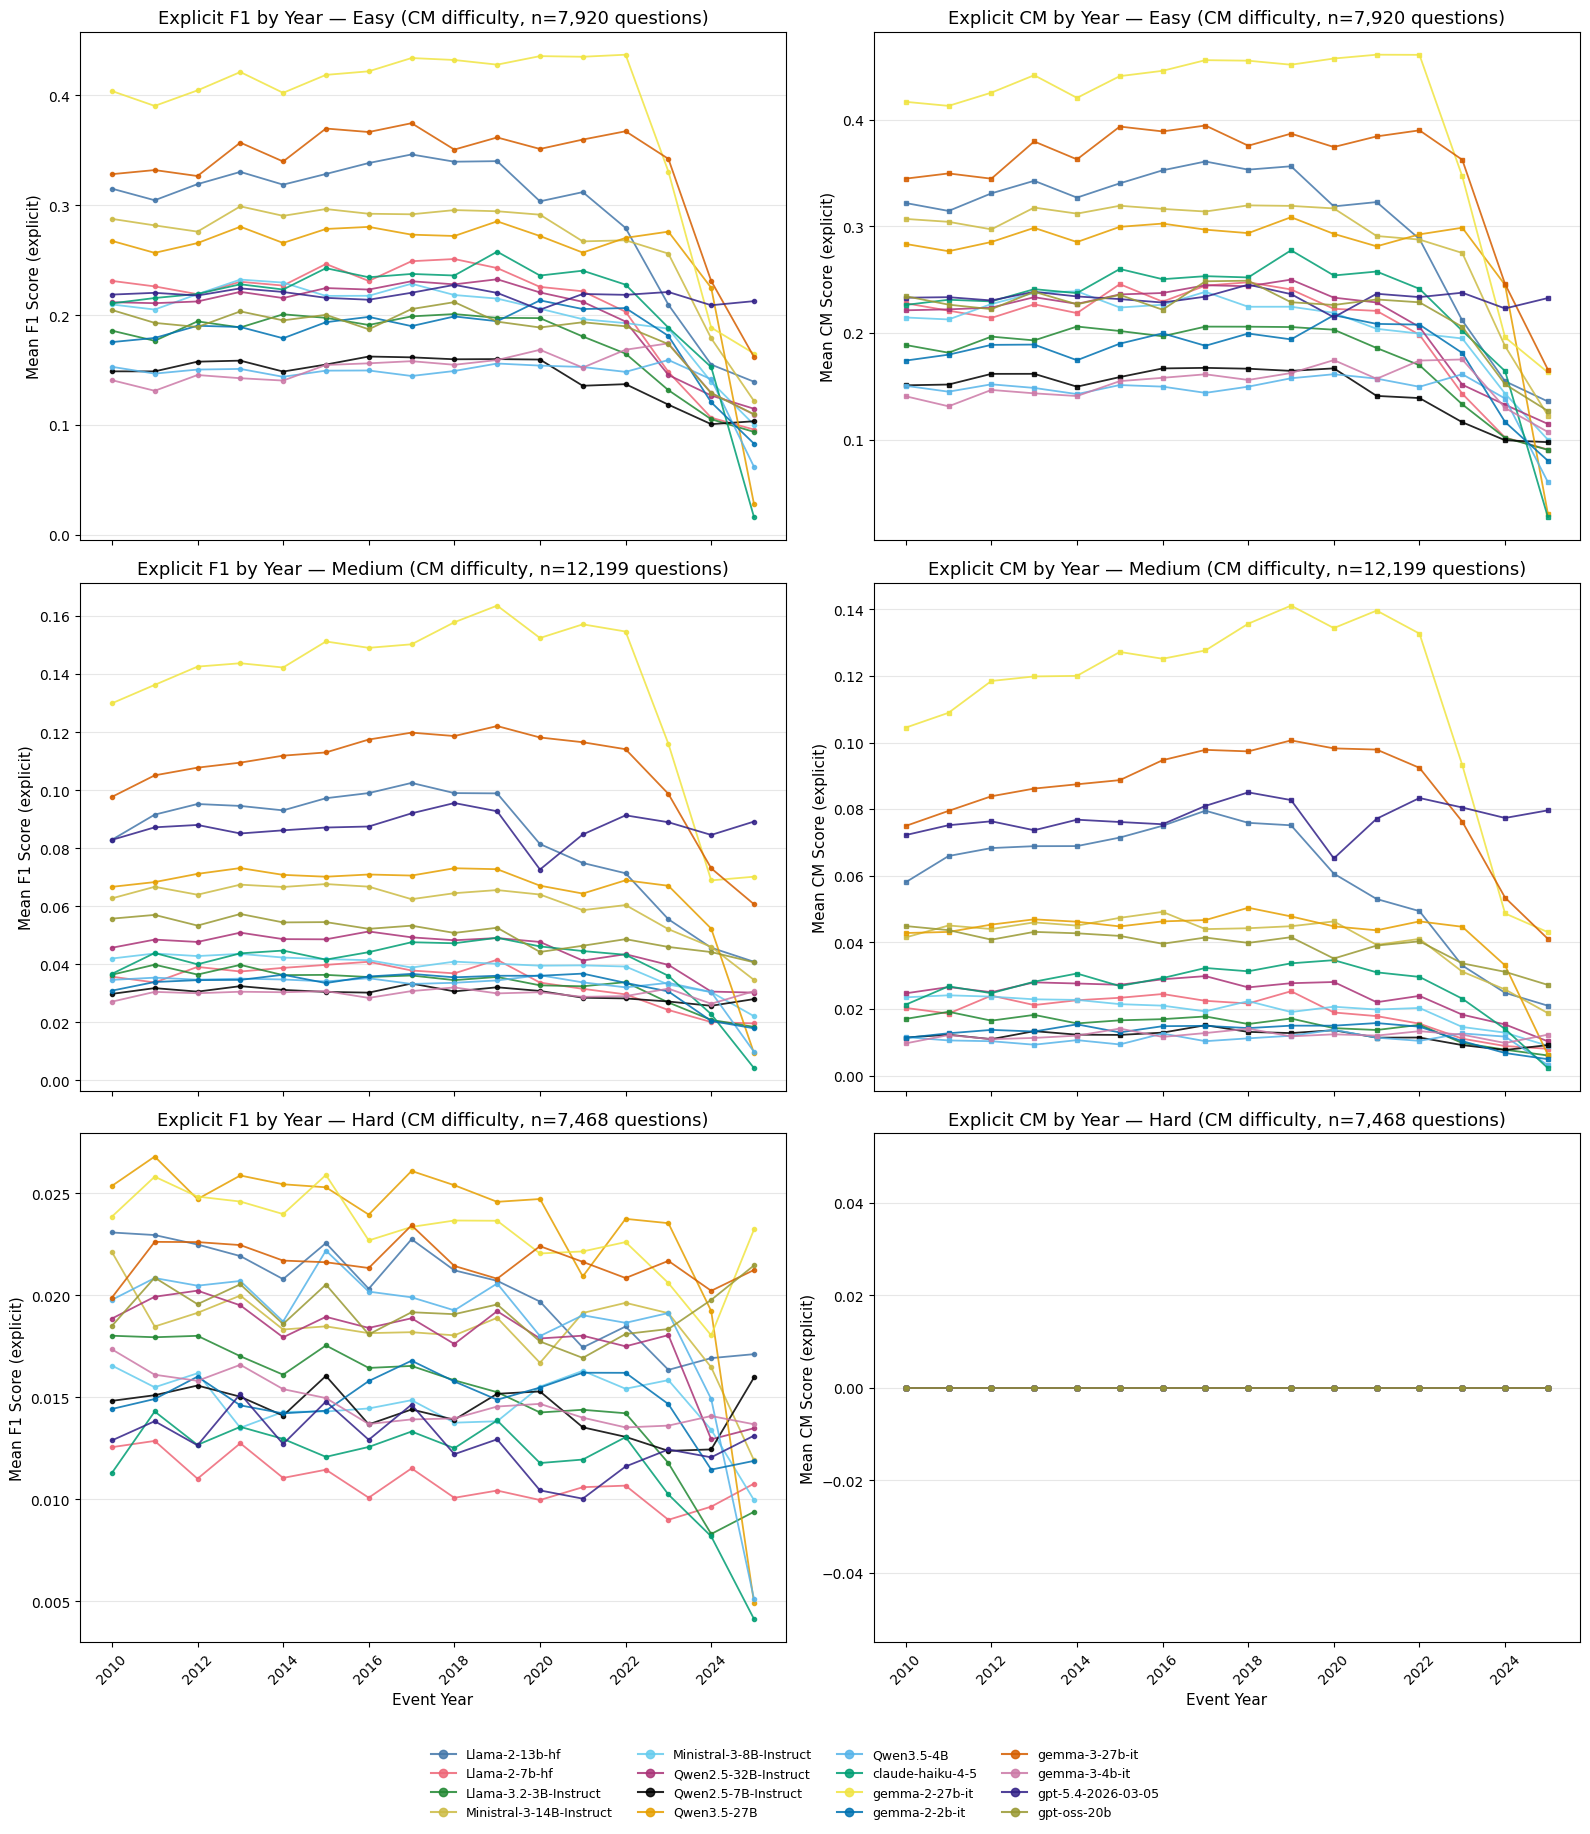


=== 8b-explicit: Explicit scores by F1-Based Difficulty (avg F1 by question) ===



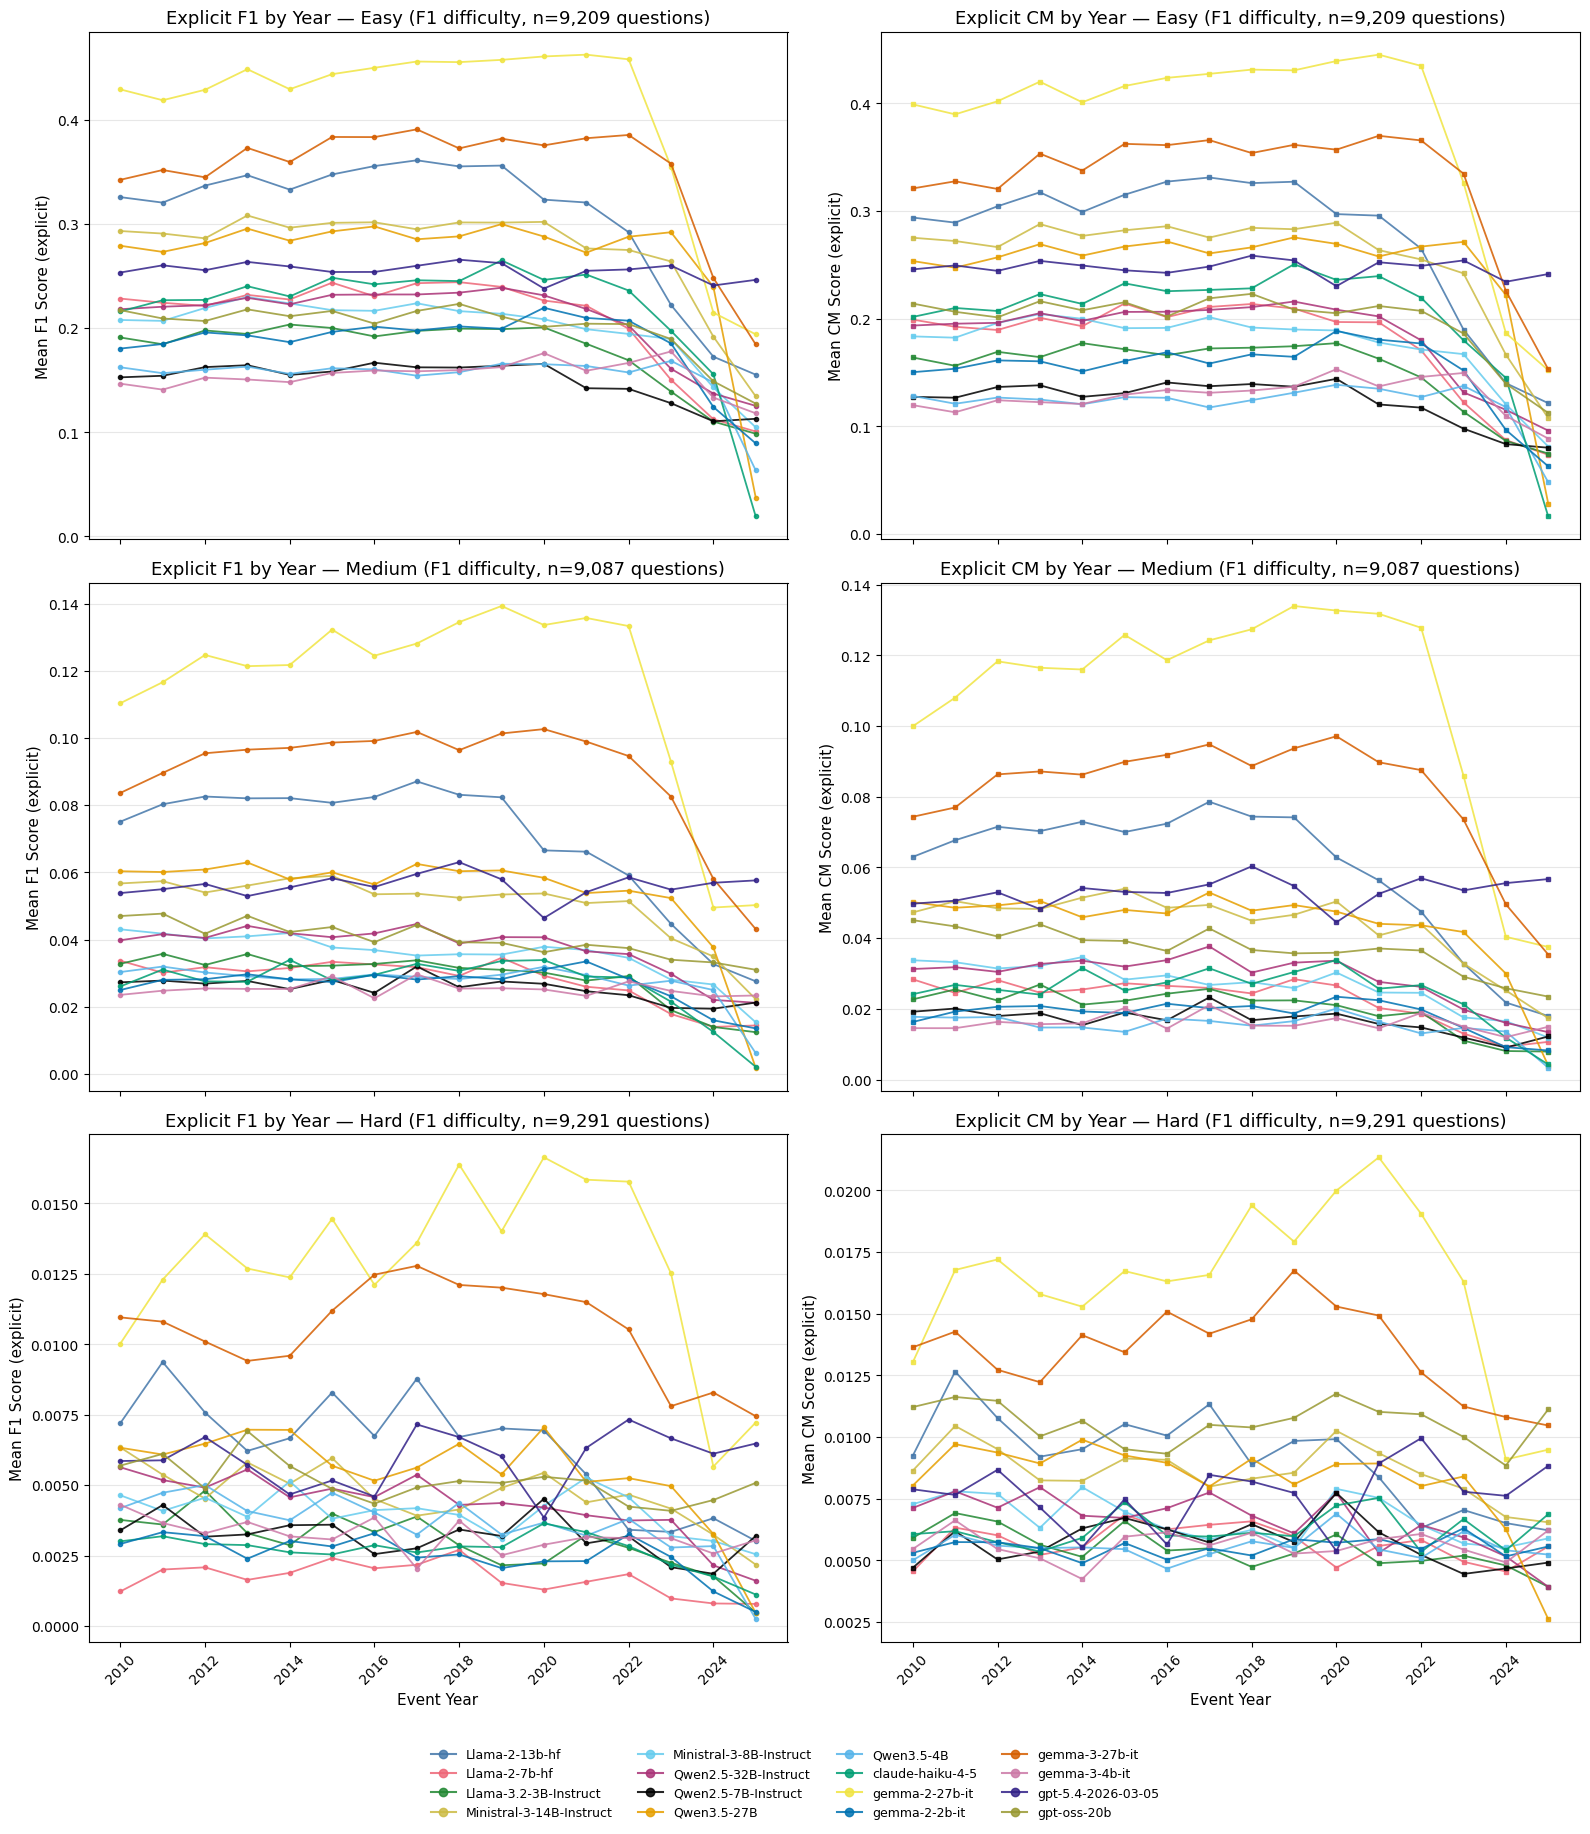


=== Difficulty consistency check (per question_id) ===
CM-based difficulty unique per question: True
F1-based difficulty unique per question: True


In [37]:
# 8a/8b (explicit): Per-model explicit F1 & CM by year, filtered by difficulty category
# Uses scores_df (columns: explicit_f1, explicit_cm, etc.) merged with df_base difficulty labels.

from matplotlib.lines import Line2D

_model_names_exp = sorted(scores_df["model_name"].unique())
_diff_order = ["Easy", "Medium", "Hard"]

model_to_color = {m: MODEL_COLORS[i % len(MODEL_COLORS)] for i, m in enumerate(_model_names_exp)}

# Pivot scores_df to wide: one row per (question, event_year) with f1_<model> and cm_<model> columns
_piv = scores_df[["question", "event_year", "model_name", "explicit_f1", "explicit_cm"]].copy()
_piv_f1 = _piv.pivot_table(index=["question", "event_year"], columns="model_name",
                            values="explicit_f1", aggfunc="first")
_piv_f1.columns = [f"f1_{m}" for m in _piv_f1.columns]
_piv_cm = _piv.pivot_table(index=["question", "event_year"], columns="model_name",
                            values="explicit_cm", aggfunc="first")
_piv_cm.columns = [f"cm_{m}" for m in _piv_cm.columns]

_wide_exp = _piv_f1.join(_piv_cm).reset_index()

# Merge with df_base to get difficulty labels and event_year alignment
_df_plot_exp = df_base[["question", "event_year", "difficulty", "difficulty_f1"]].merge(
    _wide_exp, on=["question", "event_year"], how="left"
)

f1_cols = [f"f1_{m}" for m in _model_names_exp]
cm_cols = [f"cm_{m}" for m in _model_names_exp]

###########################
# ===== 8a-explicit: By Contains-Match Difficulty =====
print("=== 8a-explicit: Explicit scores by Contains-Match Difficulty (any-year-correct) ===\n")
fig, axes = plt.subplots(len(_diff_order), 2, figsize=(16, 6 * len(_diff_order)), sharex=True)

for row, diff in enumerate(_diff_order):
    subset = _df_plot_exp[_df_plot_exp["difficulty"] == diff]
    n_questions = subset["question"].nunique()
    yearly_f1 = subset.groupby("event_year")[f1_cols].mean().sort_index()
    yearly_cm = subset.groupby("event_year")[cm_cols].mean().sort_index()

    for idx, m in enumerate(_model_names_exp):
        axes[row, 0].plot(
            yearly_f1.index, yearly_f1[f"f1_{m}"],
            marker="o", markersize=3, linewidth=1.3,
            color=model_to_color[m], label=m, alpha=0.85,
        )
        axes[row, 1].plot(
            yearly_cm.index, yearly_cm[f"cm_{m}"],
            marker="s", markersize=3, linewidth=1.3,
            color=model_to_color[m], label=m, alpha=0.85,
        )
    axes[row, 0].set_ylabel("Mean F1 Score (explicit)", fontsize=11)
    axes[row, 0].set_title(f"Explicit F1 by Year — {diff} (CM difficulty, n={n_questions:,} questions)", fontsize=13)
    axes[row, 0].grid(axis="y", alpha=0.3)
    axes[row, 1].set_ylabel("Mean CM Score (explicit)", fontsize=11)
    axes[row, 1].set_title(f"Explicit CM by Year — {diff} (CM difficulty, n={n_questions:,} questions)", fontsize=13)
    axes[row, 1].grid(axis="y", alpha=0.3)

axes[-1, 0].set_xlabel("Event Year", fontsize=11)
axes[-1, 1].set_xlabel("Event Year", fontsize=11)
axes[-1, 0].tick_params(axis="x", rotation=45)
axes[-1, 1].tick_params(axis="x", rotation=45)

legend_elements = [
    Line2D([0], [0], color=model_to_color[m], marker="o", markersize=6,
           linestyle='-', label=m, linewidth=1.5, alpha=0.85)
    for m in _model_names_exp
]
fig.legend(handles=legend_elements, loc='lower center', ncol=min(4, len(_model_names_exp)),
           fontsize=9, bbox_to_anchor=(0.5, -0.02), frameon=False)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()


###########################
# ===== 8b-explicit: By F1-Based Difficulty =====
print("\n=== 8b-explicit: Explicit scores by F1-Based Difficulty (avg F1 by question) ===\n")
fig, axes = plt.subplots(len(_diff_order), 2, figsize=(16, 6 * len(_diff_order)), sharex=True)

for row, diff in enumerate(_diff_order):
    subset = _df_plot_exp[_df_plot_exp["difficulty_f1"] == diff]
    n_questions = subset["question"].nunique()
    yearly_f1 = subset.groupby("event_year")[f1_cols].mean().sort_index()
    yearly_cm = subset.groupby("event_year")[cm_cols].mean().sort_index()

    for idx, m in enumerate(_model_names_exp):
        axes[row, 0].plot(
            yearly_f1.index, yearly_f1[f"f1_{m}"],
            marker="o", markersize=3, linewidth=1.3,
            color=model_to_color[m], label=m, alpha=0.85,
        )
        axes[row, 1].plot(
            yearly_cm.index, yearly_cm[f"cm_{m}"],
            marker="s", markersize=3, linewidth=1.3,
            color=model_to_color[m], label=m, alpha=0.85,
        )
    axes[row, 0].set_ylabel("Mean F1 Score (explicit)", fontsize=11)
    axes[row, 0].set_title(f"Explicit F1 by Year — {diff} (F1 difficulty, n={n_questions:,} questions)", fontsize=13)
    axes[row, 0].grid(axis="y", alpha=0.3)
    axes[row, 1].set_ylabel("Mean CM Score (explicit)", fontsize=11)
    axes[row, 1].set_title(f"Explicit CM by Year — {diff} (F1 difficulty, n={n_questions:,} questions)", fontsize=13)
    axes[row, 1].grid(axis="y", alpha=0.3)

axes[-1, 0].set_xlabel("Event Year", fontsize=11)
axes[-1, 1].set_xlabel("Event Year", fontsize=11)
axes[-1, 0].tick_params(axis="x", rotation=45)
axes[-1, 1].tick_params(axis="x", rotation=45)

fig.legend(handles=legend_elements, loc='lower center', ncol=min(4, len(_model_names_exp)),
           fontsize=9, bbox_to_anchor=(0.5, -0.02), frameon=False)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

# Validate difficulty consistency
_cm_uniques = df_base.groupby("question_id")["difficulty"].nunique(dropna=False)
_f1_uniques = df_base.groupby("question_id")["difficulty_f1"].nunique(dropna=False)

_cm_ok = int(_cm_uniques.max()) == 1
_f1_ok = int(_f1_uniques.max()) == 1

print("\n=== Difficulty consistency check (per question_id) ===")
print(f"CM-based difficulty unique per question: {_cm_ok}")
print(f"F1-based difficulty unique per question: {_f1_ok}")

if not (_cm_ok and _f1_ok):
    bad_cm = _cm_uniques[_cm_uniques > 1].index.tolist()
    bad_f1 = _f1_uniques[_f1_uniques > 1].index.tolist()
    print(f"Question IDs with multiple CM difficulties: {bad_cm[:10]}")
    print(f"Question IDs with multiple F1 difficulties: {bad_f1[:10]}")

del _cm_uniques, _f1_uniques, _cm_ok, _f1_ok
del _df_plot_exp, _piv, _piv_f1, _piv_cm, _wide_exp

In [38]:
# Detailed statistics per difficulty group
diff_order = ["Easy", "Medium", "Hard"]

print("=== 6a: Contains-Match Difficulty (any-year-correct) — Statistics ===")
group_stats = df_base.groupby("difficulty").agg(
    count=("question", "size"),
    avg_models_any_year_correct=("models_any_year_correct", "mean"),
    avg_models_correct_cm=("models_correct_cm", "mean"),
    avg_f1=("avg_f1", "mean"),
    pct_numerical=("answer_type", lambda x: (x == "numerical").mean() * 100),
).reindex(diff_order).round(3)
display(group_stats)


=== 6a: Contains-Match Difficulty (any-year-correct) — Statistics ===


,count,avg_models_any_year_correct,avg_models_correct_cm,avg_f1,pct_numerical
difficulty,,,,,
Easy,107883,12.436,3.794,0.226,2.379
Medium,158270,3.705,0.620,0.057,4.286
Hard,92424,0.000,0.000,0.017,4.795



=== 6b: F1-Based Difficulty — Statistics ===


,count,avg_f1_by_question,avg_models_correct_cm,avg_f1,pct_numerical
difficulty_f1,,,,,
Easy,121924,0.237,3.427,0.237,1.169
Medium,118722,0.047,0.628,0.047,3.687
Hard,117931,0.005,0.128,0.005,6.767


In [39]:
# Category breakdown within each difficulty group

print("=== 6a: Contains-Match Difficulty (any-year-correct) ===")
ct_cm = pd.crosstab(df_base["difficulty"], df_base["categories"], margins=True)
ct_cm = ct_cm.reindex(index=diff_order + ["All"])
print("Category counts:")
display(ct_cm)

ct_cm_pct = pd.crosstab(df_base["difficulty"], df_base["categories"], normalize="index") * 100
ct_cm_pct = ct_cm_pct.reindex(index=diff_order)
print("\nCategory %:")
display(ct_cm_pct.round(1))


=== 6a: Contains-Match Difficulty (any-year-correct) ===
Category counts:


categories,culture,politics,sport,All
difficulty,,,,
Easy,31755,1030,75098,107883
Medium,54800,1885,101585,158270
Hard,43156,1405,47863,92424
All,129711,4320,224546,358577



Category %:


categories,culture,politics,sport
difficulty,,,
Easy,29.4,1.0,69.6
Medium,34.6,1.2,64.2
Hard,46.7,1.5,51.8



=== 6b: F1-Based Difficulty ===
Category counts:


categories,culture,politics,sport,All
difficulty_f1,,,,
Easy,32111,1706,88107,121924
Medium,45841,1163,71718,118722
Hard,51759,1451,64721,117931
All,129711,4320,224546,358577



Category %:


categories,culture,politics,sport
difficulty_f1,,,
Easy,26.3,1.4,72.3
Medium,38.6,1.0,60.4
Hard,43.9,1.2,54.9


In [40]:
# Top relationships in each difficulty group (CM any-year-correct)
print("=== 6a: Contains-Match Difficulty — Top Relationships ===")
for grp in diff_order:
    subset = df_base[df_base["difficulty"] == grp]
    top_rels = subset["relationship"].value_counts().head(10)
    print(f"\n--- {grp.upper()} (n={len(subset):,}) ---")
    for rel, cnt in top_rels.items():
        print(f"  {rel:40s} {cnt:>7,} ({cnt/len(subset)*100:.1f}%)")


=== 6a: Contains-Match Difficulty — Top Relationships ===

--- EASY (n=107,883) ---
  winner                                    27,436 (25.4%)
  runner-up                                  6,319 (5.9%)
  champion                                   4,579 (4.2%)
  nominees                                   3,423 (3.2%)
  venue                                      2,699 (2.5%)
  team                                       2,432 (2.3%)
  location                                   2,147 (2.0%)
  position                                   2,058 (1.9%)
  third place                                1,737 (1.6%)
  network                                    1,585 (1.5%)

--- MEDIUM (n=158,270) ---
  winner                                    38,518 (24.3%)
  runner-up                                  6,277 (4.0%)
  champion                                   4,765 (3.0%)
  venue                                      3,919 (2.5%)
  third place                                3,866 (2.4%)
  team          

In [41]:
# Sample questions from each difficulty group (CM any-year-correct)
print("=== 6a: Contains-Match Difficulty (any-year-correct) — Samples ===")
for grp in diff_order:
    subset = df_base[df_base["difficulty"] == grp]
    sample = subset.sample(n=min(5, len(subset)), random_state=42)
    print(f"\n--- {grp.upper()} (n={len(subset):,}) ---")
    for _, row in sample.iterrows():
        print(f"  Q: {row['question']}")
        print(f"  A: {row['answer_first']}  |  type={row['answer_type']}  |  cat={row['categories']}")
        print(f"     models_any_year_correct={row['models_any_year_correct']}, "
              f"avg_f1_by_question={row['avg_f1_by_question']:.3f}")
        print()


=== 6a: Contains-Match Difficulty (any-year-correct) — Samples ===



--- EASY (n=107,883) ---
  Q: Who won the bronze medal in the Table Tennis World Cup men's singles?
  A: Wong Chun-ting  |  type=text  |  cat=sport
     models_any_year_correct=12, avg_f1_by_question=0.104

  Q: what grand prix did the Silverstone Circuit host?
  A: British Grand Prix  |  type=text  |  cat=sport
     models_any_year_correct=16, avg_f1_by_question=0.987

  Q: what was the winner of the Satellite Award for Best Animated or Mixed Media Feature?
  A: The Boy and the Heron  |  type=text  |  cat=culture
     models_any_year_correct=13, avg_f1_by_question=0.133

  Q: Where was the World Championships in women's freestyle wrestling bantamweight held?
  A: Las Vegas  |  type=text  |  cat=sport
     models_any_year_correct=15, avg_f1_by_question=0.397

  Q: what film did the Online Film Critics Society Award for Best Supporting Actress winner star in?
  A: The Tree of Life  |  type=text  |  cat=culture
     models_any_year_correct=12, avg_f1_by_question=0.127


--- MEDIUM (n=15

=== 8a-explicit: Explicit scores by Contains-Match Difficulty (any-year-correct) ===



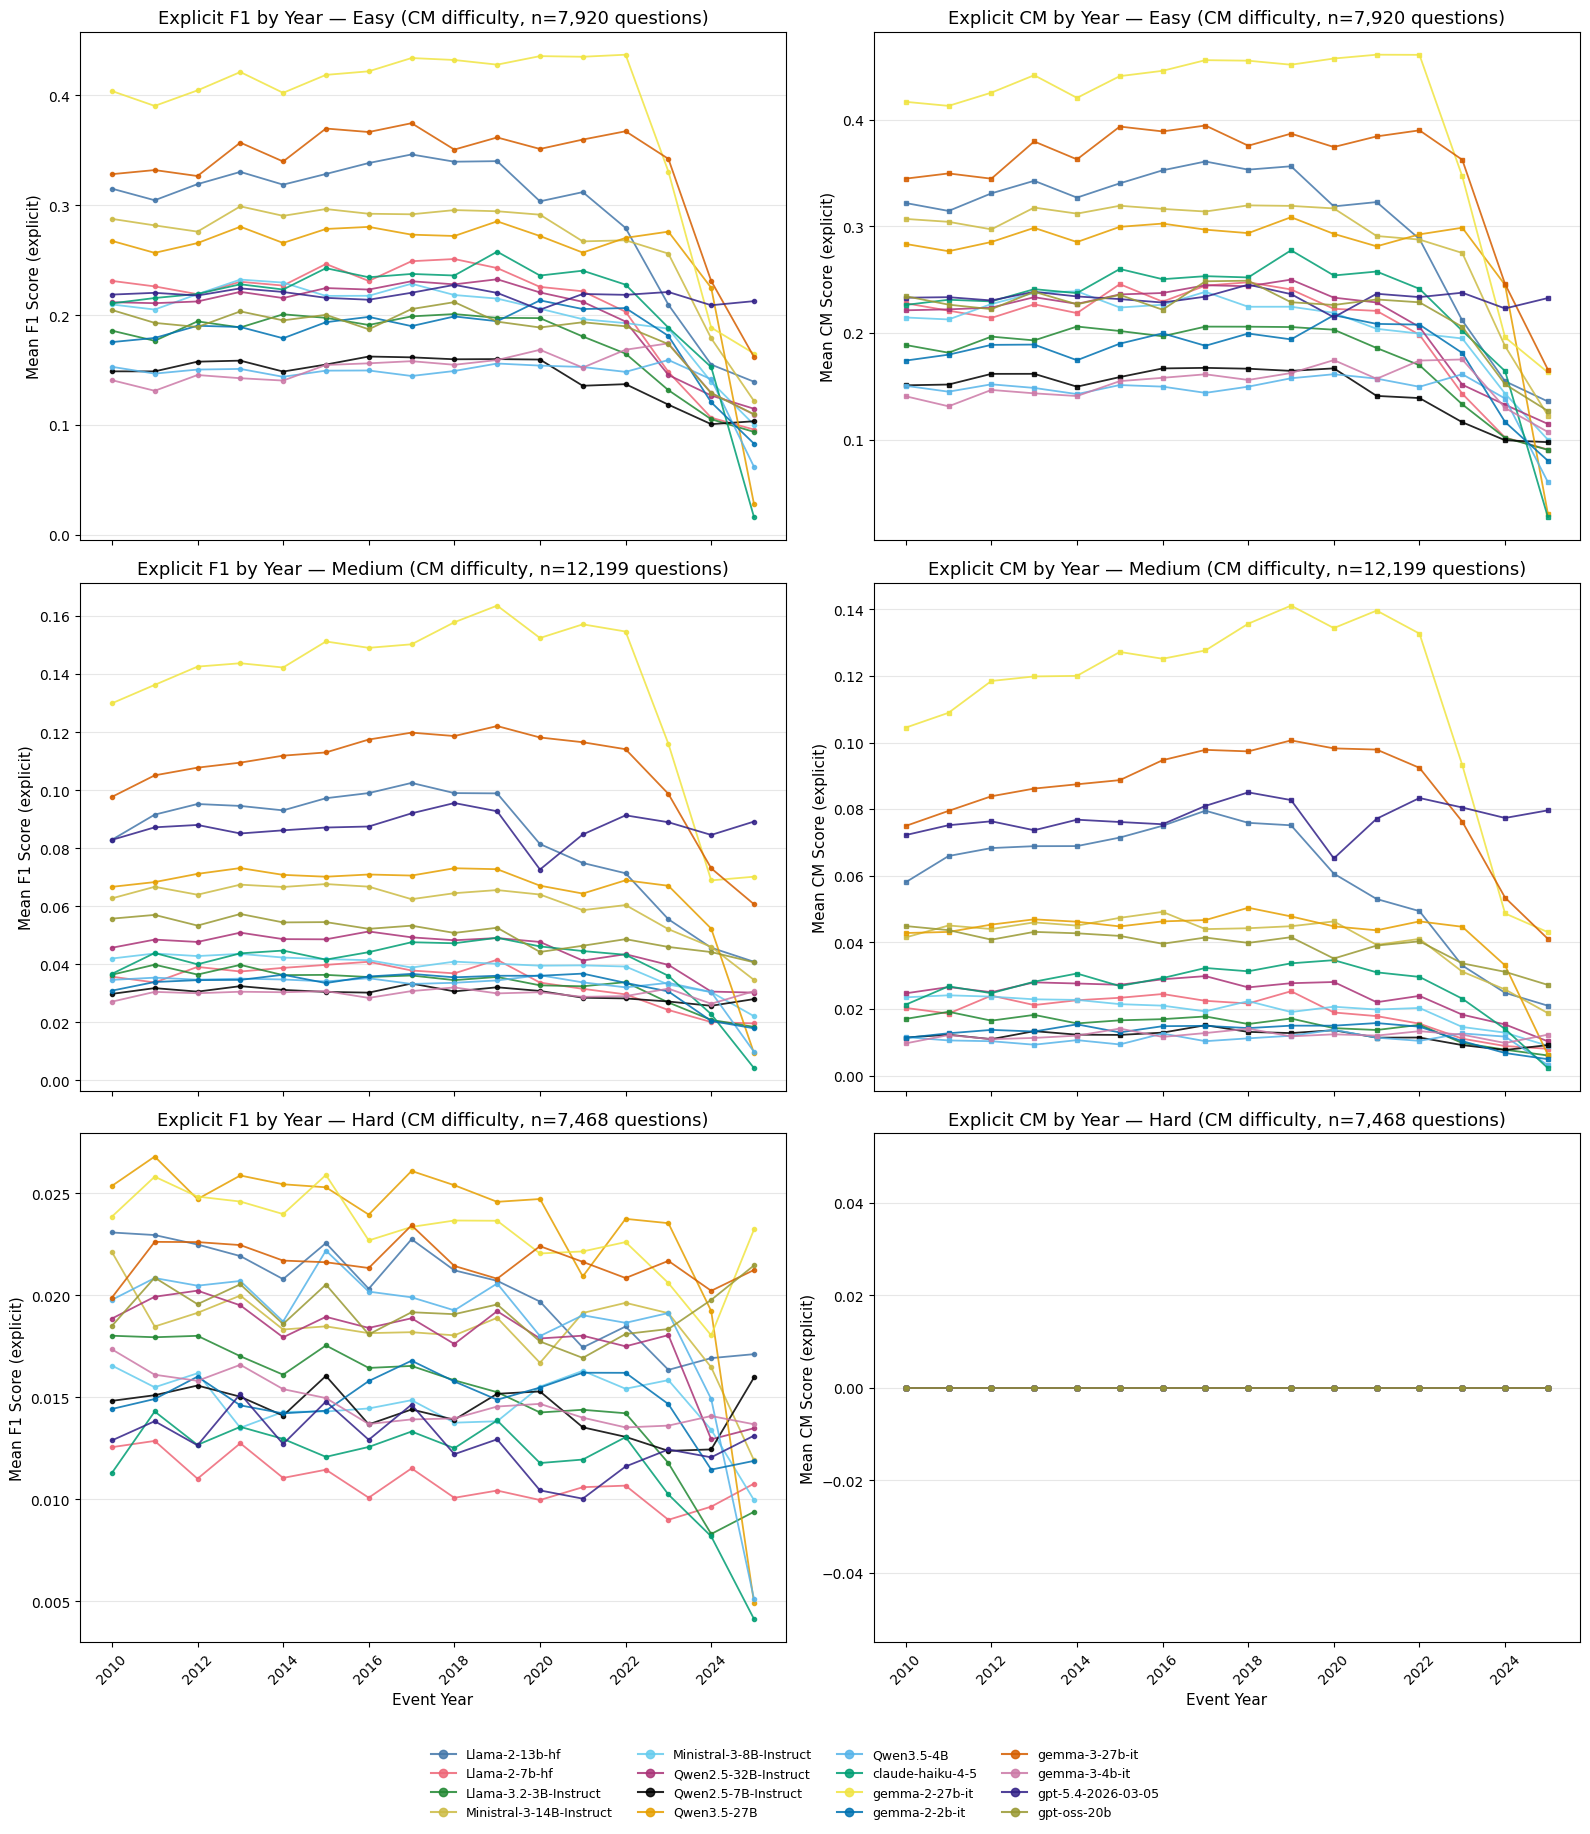


=== 8b-explicit: Explicit scores by F1-Based Difficulty (avg F1 by question) ===



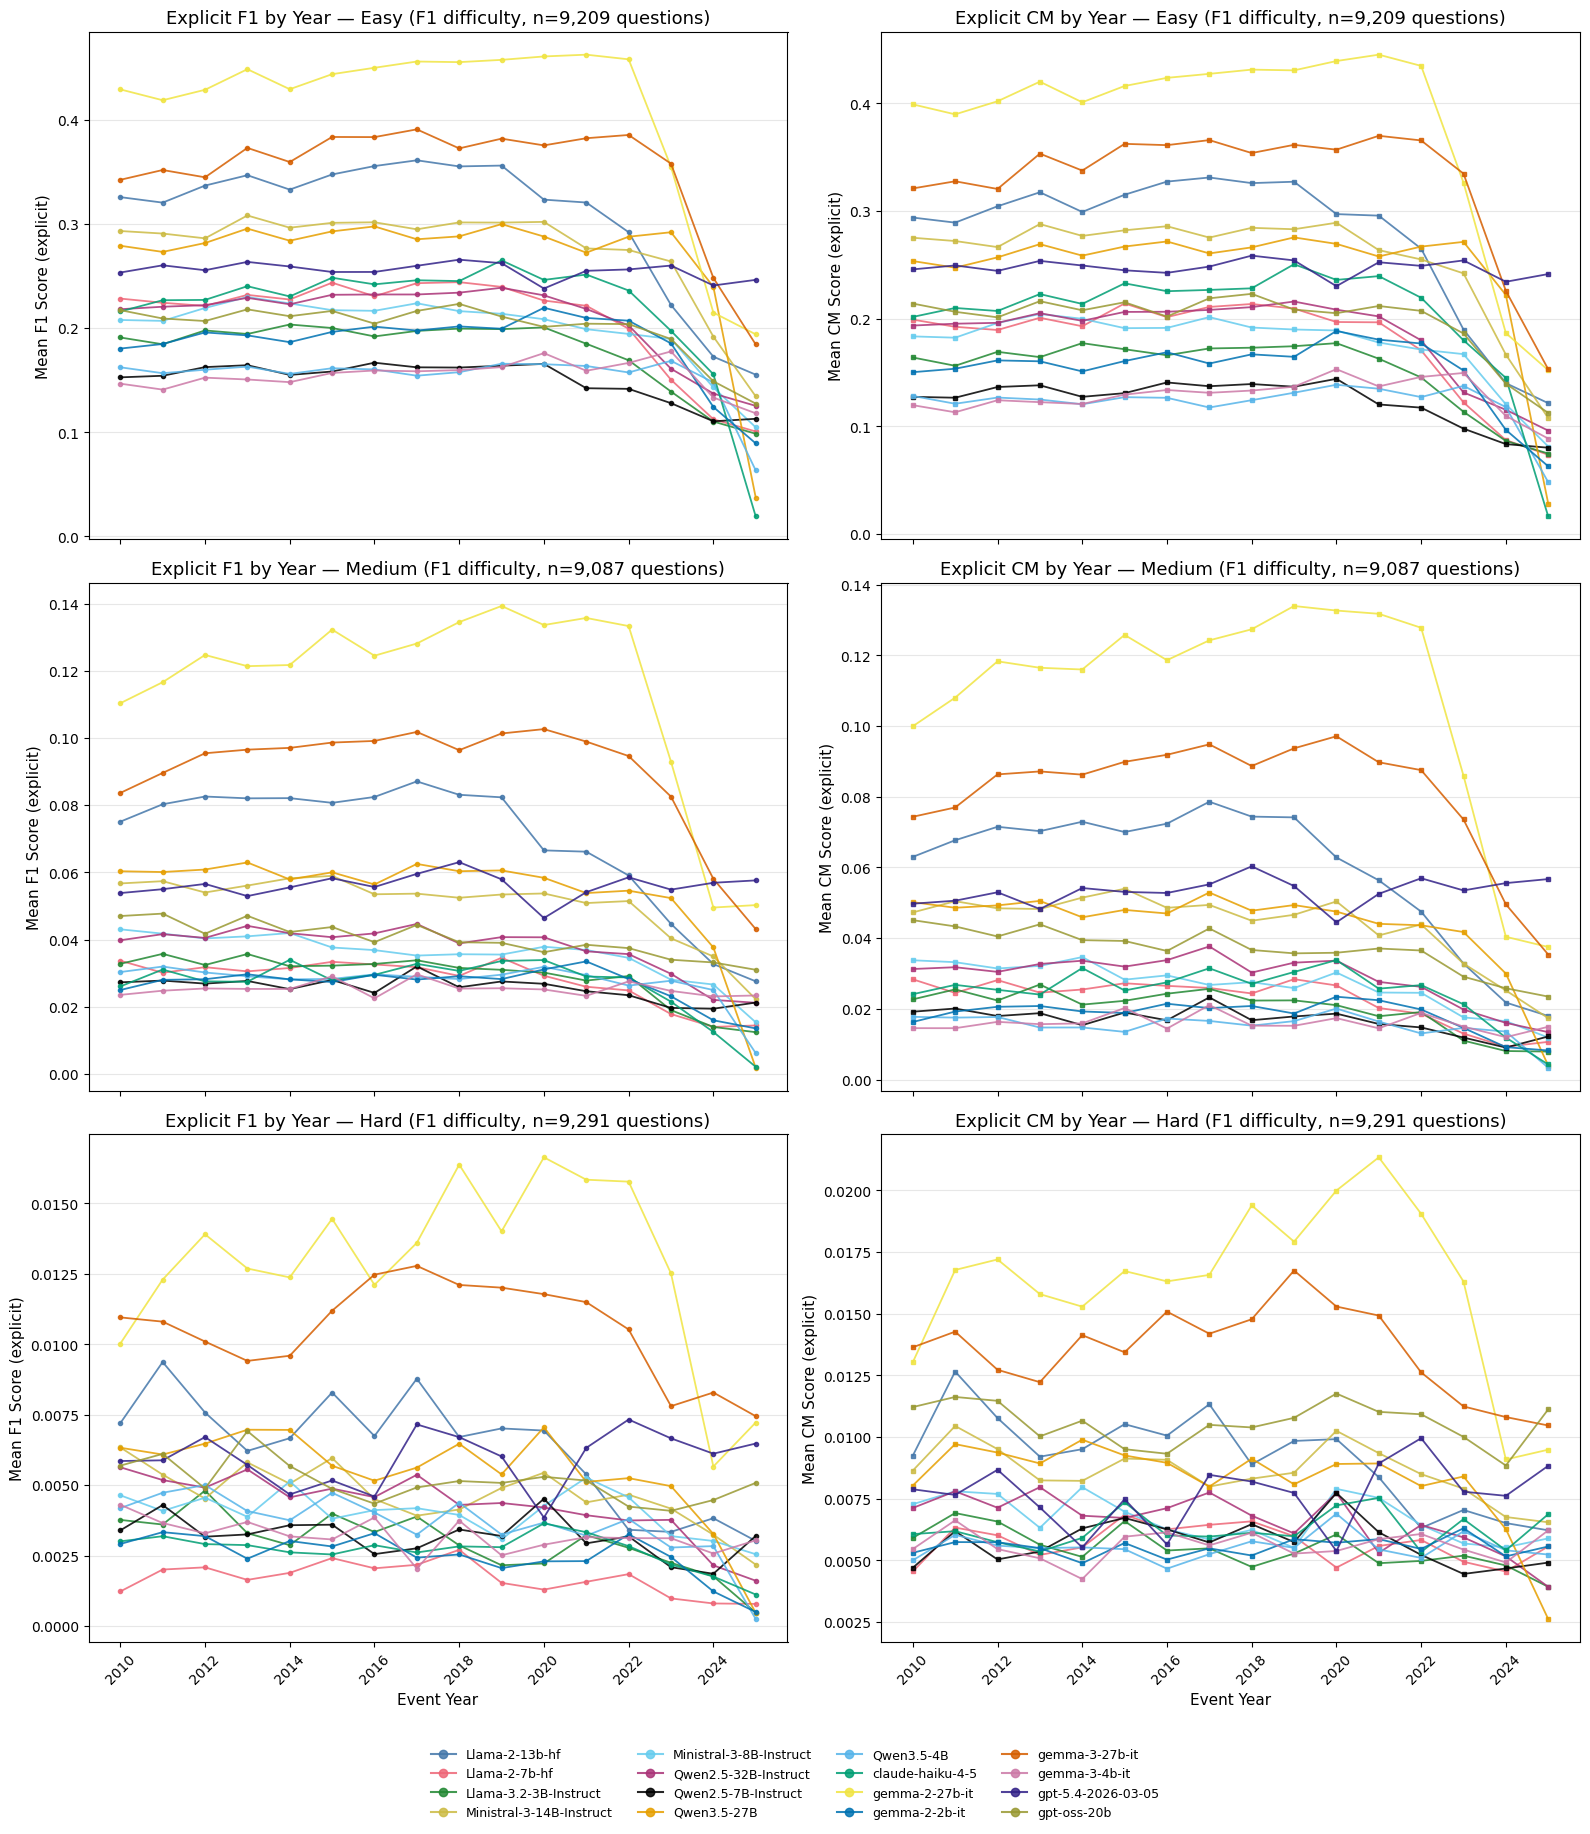


=== Difficulty consistency check (per question_id) ===
CM-based difficulty unique per question: True
F1-based difficulty unique per question: True


In [42]:
# 8a/8b (explicit): Per-model explicit F1 & CM by year, filtered by difficulty category
# Uses scores_df (columns: explicit_f1, explicit_cm) merged with df_base difficulty labels.

from matplotlib.lines import Line2D

_model_names_exp = sorted(scores_df["model_name"].unique())
_diff_order = ["Easy", "Medium", "Hard"]

model_to_color = {m: MODEL_COLORS[i % len(MODEL_COLORS)] for i, m in enumerate(_model_names_exp)}

# Pivot scores_df to wide format: f1_<model> and cm_<model> columns
_piv = scores_df[["question", "event_year", "model_name", "explicit_f1", "explicit_cm"]].copy()
_piv_f1 = _piv.pivot_table(index=["question", "event_year"], columns="model_name",
                            values="explicit_f1", aggfunc="first")
_piv_f1.columns = [f"f1_{m}" for m in _piv_f1.columns]
_piv_cm = _piv.pivot_table(index=["question", "event_year"], columns="model_name",
                            values="explicit_cm", aggfunc="first")
_piv_cm.columns = [f"cm_{m}" for m in _piv_cm.columns]
_wide_exp = _piv_f1.join(_piv_cm).reset_index()

# Merge with df_base to get difficulty labels
_df_plot_exp = df_base[["question", "event_year", "difficulty", "difficulty_f1"]].merge(
    _wide_exp, on=["question", "event_year"], how="left"
)

f1_cols = [f"f1_{m}" for m in _model_names_exp]
cm_cols = [f"cm_{m}" for m in _model_names_exp]

###########################
# ===== 8a-explicit: By Contains-Match Difficulty =====
print("=== 8a-explicit: Explicit scores by Contains-Match Difficulty (any-year-correct) ===\n")
fig, axes = plt.subplots(len(_diff_order), 2, figsize=(16, 6 * len(_diff_order)), sharex=True)

for row, diff in enumerate(_diff_order):
    subset = _df_plot_exp[_df_plot_exp["difficulty"] == diff]
    n_questions = subset["question"].nunique()
    yearly_f1 = subset.groupby("event_year")[f1_cols].mean().sort_index()
    yearly_cm = subset.groupby("event_year")[cm_cols].mean().sort_index()

    for idx, m in enumerate(_model_names_exp):
        axes[row, 0].plot(
            yearly_f1.index,
            yearly_f1[f"f1_{m}"],
            marker="o",
            markersize=3,
            linewidth=1.3,
            color=model_to_color[m],
            label=m,
            alpha=0.85,
        )
        axes[row, 1].plot(
            yearly_cm.index,
            yearly_cm[f"cm_{m}"],
            marker="s",
            markersize=3,
            linewidth=1.3,
            color=model_to_color[m],
            label=m,
            alpha=0.85,
        )
    axes[row, 0].set_ylabel("Mean F1 Score (explicit)", fontsize=11)
    axes[row, 0].set_title(f"Explicit F1 by Year — {diff} (CM difficulty, n={n_questions:,} questions)", fontsize=13)
    axes[row, 0].grid(axis="y", alpha=0.3)
    axes[row, 1].set_ylabel("Mean CM Score (explicit)", fontsize=11)
    axes[row, 1].set_title(f"Explicit CM by Year — {diff} (CM difficulty, n={n_questions:,} questions)", fontsize=13)
    axes[row, 1].grid(axis="y", alpha=0.3)

axes[-1, 0].set_xlabel("Event Year", fontsize=11)
axes[-1, 1].set_xlabel("Event Year", fontsize=11)
axes[-1, 0].tick_params(axis="x", rotation=45)
axes[-1, 1].tick_params(axis="x", rotation=45)

legend_elements = [
    Line2D([0], [0], color=model_to_color[m], marker="o", markersize=6,
           linestyle='-', label=m, linewidth=1.5, alpha=0.85)
    for m in _model_names_exp
]
fig.legend(handles=legend_elements, loc='lower center', ncol=min(4, len(_model_names_exp)),
           fontsize=9, bbox_to_anchor=(0.5, -0.02), frameon=False)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()


###########################
# ===== 8b-explicit: By F1-Based Difficulty =====
print("\n=== 8b-explicit: Explicit scores by F1-Based Difficulty (avg F1 by question) ===\n")
fig, axes = plt.subplots(len(_diff_order), 2, figsize=(16, 6 * len(_diff_order)), sharex=True)

for row, diff in enumerate(_diff_order):
    subset = _df_plot_exp[_df_plot_exp["difficulty_f1"] == diff]
    n_questions = subset["question"].nunique()
    yearly_f1 = subset.groupby("event_year")[f1_cols].mean().sort_index()
    yearly_cm = subset.groupby("event_year")[cm_cols].mean().sort_index()

    for idx, m in enumerate(_model_names_exp):
        axes[row, 0].plot(
            yearly_f1.index,
            yearly_f1[f"f1_{m}"],
            marker="o",
            markersize=3,
            linewidth=1.3,
            color=model_to_color[m],
            label=m,
            alpha=0.85,
        )
        axes[row, 1].plot(
            yearly_cm.index,
            yearly_cm[f"cm_{m}"],
            marker="s",
            markersize=3,
            linewidth=1.3,
            color=model_to_color[m],
            label=m,
            alpha=0.85,
        )
    axes[row, 0].set_ylabel("Mean F1 Score (explicit)", fontsize=11)
    axes[row, 0].set_title(f"Explicit F1 by Year — {diff} (F1 difficulty, n={n_questions:,} questions)", fontsize=13)
    axes[row, 0].grid(axis="y", alpha=0.3)
    axes[row, 1].set_ylabel("Mean CM Score (explicit)", fontsize=11)
    axes[row, 1].set_title(f"Explicit CM by Year — {diff} (F1 difficulty, n={n_questions:,} questions)", fontsize=13)
    axes[row, 1].grid(axis="y", alpha=0.3)

axes[-1, 0].set_xlabel("Event Year", fontsize=11)
axes[-1, 1].set_xlabel("Event Year", fontsize=11)
axes[-1, 0].tick_params(axis="x", rotation=45)
axes[-1, 1].tick_params(axis="x", rotation=45)

# Common legend at the bottom
fig.legend(handles=legend_elements, loc='lower center', ncol=min(4, len(_model_names_exp)),
           fontsize=9, bbox_to_anchor=(0.5, -0.02), frameon=False)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

# Validate that each question_id maps to exactly one difficulty label in each scheme
_cm_uniques = df_base.groupby("question_id")["difficulty"].nunique(dropna=False)
_f1_uniques = df_base.groupby("question_id")["difficulty_f1"].nunique(dropna=False)

_cm_ok = int(_cm_uniques.max()) == 1
_f1_ok = int(_f1_uniques.max()) == 1

print("\n=== Difficulty consistency check (per question_id) ===")
print(f"CM-based difficulty unique per question: {_cm_ok}")
print(f"F1-based difficulty unique per question: {_f1_ok}")

if not (_cm_ok and _f1_ok):
    bad_cm = _cm_uniques[_cm_uniques > 1].index.tolist()
    bad_f1 = _f1_uniques[_f1_uniques > 1].index.tolist()
    print(f"Question IDs with multiple CM difficulties: {bad_cm[:10]}")
    print(f"Question IDs with multiple F1 difficulties: {bad_f1[:10]}")

del _cm_uniques, _f1_uniques, _cm_ok, _f1_ok

del _df_plot_exp, _piv, _piv_f1, _piv_cm, _wide_exp

In [43]:
# Per-model relative F1 & CM by year, filtered by difficulty category
# Sources data from scores_df (relative_f1, relative_cm) + df_base difficulty labels.

_model_names = sorted(scores_df["model_name"].unique())
_diff_order = ["Easy", "Medium", "Hard"]
_model_colors = {m: MODEL_COLORS[i % len(MODEL_COLORS)] for i, m in enumerate(_model_names)}

# Pivot relative scores to wide format
_piv = scores_df[["question", "event_year", "model_name", "relative_f1", "relative_cm"]].copy()
_piv_f1 = _piv.pivot_table(index=["question", "event_year"], columns="model_name",
                            values="relative_f1", aggfunc="first")
_piv_f1.columns = [f"f1_{m}" for m in _piv_f1.columns]
_piv_cm = _piv.pivot_table(index=["question", "event_year"], columns="model_name",
                            values="relative_cm", aggfunc="first")
_piv_cm.columns = [f"cm_{m}" for m in _piv_cm.columns]

_df_plot = df_base[["question", "event_year", "difficulty", "difficulty_f1"]].merge(
    _piv_f1.join(_piv_cm).reset_index(), on=["question", "event_year"], how="left"
)

f1_cols = [f"f1_{m}" for m in _model_names]
cm_cols = [f"cm_{m}" for m in _model_names]

def _plot_by_difficulty(df, diff_col, diff_label, diff_order, models, colors, f1_cols, cm_cols):
    fig, axes = plt.subplots(len(diff_order), 2, figsize=(16, 6 * len(diff_order)), sharex=False)
    for row, diff in enumerate(diff_order):
        subset = df[df[diff_col] == diff]
        n_q = subset["question"].nunique()
        yearly_f1 = subset.groupby("event_year")[f1_cols].mean().sort_index()
        yearly_cm = subset.groupby("event_year")[cm_cols].mean().sort_index()
        for m in models:
            axes[row, 0].plot(yearly_f1.index, yearly_f1[f"f1_{m}"], marker="o", markersize=3,
                              linewidth=1.3, color=colors[m], label=m, alpha=0.85)
            axes[row, 1].plot(yearly_cm.index, yearly_cm[f"cm_{m}"], marker="s", markersize=3,
                              linewidth=1.3, color=colors[m], label=m, alpha=0.85)
        for ax, metric in [(axes[row, 0], "F1"), (axes[row, 1], "CM")]:
            ax.set_ylabel(f"Mean {metric} Score (relative)", fontsize=11)
            ax.set_title(f"Relative {metric} by Year — {diff} ({diff_label}, n={n_q:,} questions)", fontsize=13)
            ax.set_xlabel("Event Year", fontsize=11)
            ax.tick_params(axis="x", rotation=45)
            ax.legend(loc="upper left", fontsize=7, ncol=2)
            ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

print("=== 8a: Relative scores by Contains-Match Difficulty (any-year-correct) ===\n")
_plot_by_difficulty(_df_plot, "difficulty", "CM difficulty", _diff_order,
                    _model_names, _model_colors, f1_cols, cm_cols)

print("\n=== 8b: Relative scores by F1-Based Difficulty (avg F1 by question) ===\n")
_plot_by_difficulty(_df_plot, "difficulty_f1", "F1 difficulty", _diff_order,
                    _model_names, _model_colors, f1_cols, cm_cols)

del _df_plot, _piv, _piv_f1, _piv_cm

NameError: name '_scores_rel' is not defined

In [ ]:
# ===== Pageviews vs F1 Correlation (filter by difficulty and years) =====
# Parameter: filter by difficulty. Set to None for all data, or "Easy", "Medium", "Hard"
DIFFICULTY_FILTER = "Easy"  # e.g. "Easy", "Medium", "Hard", or None for all
# Parameter: filter by years. Set to None for all years, or a list e.g. [2015, 2016, 2017] or range(2010, 2021)
YEAR_FILTER = list(range(2022, 2024))  # e.g. list(range(2015, 2021)), or None for all years

from IPython.display import display

_model_names_pv = sorted(model_scores.keys())


def _scalar_to_number(x):
    """Best-effort conversion of nested/list-like values to a single float."""
    if isinstance(x, (list, tuple, np.ndarray)):
        if len(x) == 0:
            return np.nan
        x = x[0]
    if x is None:
        return np.nan
    if isinstance(x, float) and np.isnan(x):
        return np.nan
    return float(x)


# Build DataFrame: explicit F1 + difficulty
_df_pv = pd.DataFrame({
    "question": df_base["question"].values,
    "event_year": df_base["event_year"].values,
    "difficulty": df_base["difficulty"].values,
})
for m in _model_names_pv:
    _df_pv[f"f1_{m}"] = model_scores[m]["f1"]

# Apply difficulty filter
if DIFFICULTY_FILTER is not None:
    _df_pv = _df_pv[_df_pv["difficulty"] == DIFFICULTY_FILTER].copy()
    filter_label = f" (difficulty={DIFFICULTY_FILTER})"
else:
    filter_label = " (all difficulties)"

# Apply year filter
if YEAR_FILTER is not None:
    year_list = list(YEAR_FILTER)  # support range() or list
    _df_pv = _df_pv[_df_pv["event_year"].isin(year_list)].copy()
    filter_label += f" years={min(year_list)}–{max(year_list)}"

print(f"=== F1 vs Pageviews correlation{filter_label} ===\n")
print(f"Rows: {len(_df_pv):,}\n")

ref_file = next(BENCHMARK_DIR.glob(f"benchmark_*_{RUN_TAG}.parquet"))
import pyarrow.parquet as pq

pf_schema = pq.read_schema(ref_file)
all_columns = [f.name for f in pf_schema]
cand = [c for c in all_columns if (
    "views" in c.lower() or "page_views" in c.lower() or
    c.lower() in ["pv", "pv_count", "pvcount"] or "view_count" in c.lower() or
    "viewcount" in c.lower() or c.lower().endswith("views")
)]
if not cand:
    cand = [c for c in all_columns if ("view" in c.lower()) or ("page" in c.lower())]

pageview_col = None
if cand:
    sample_df = pd.read_parquet(ref_file, columns=cand)
    for c in cand:
        s_num = sample_df[c].map(_scalar_to_number)
        if float(s_num.notna().mean()) >= 0.5 and float(s_num.sum(skipna=True)) > 0:
            pageview_col = c
            break
    del sample_df

if pageview_col is None:
    pv_df = _df_pv.groupby(["question", "event_year"]).size().reset_index(name="pageviews")
else:
    pv_df = pd.read_parquet(ref_file, columns=["question", "event_year", pageview_col])
    pv_df["pageviews"] = pv_df[pageview_col].map(_scalar_to_number)
    pv_df = pv_df.drop(columns=[pageview_col]).dropna(subset=["pageviews"])
pv_df["event_year"] = pv_df["event_year"].astype(int)

# ENSURE pageviews > 0 for further use (explicit per instruction)
pv_df = pv_df[pv_df["pageviews"] > 0].copy()

# Merge difficulty for filtering pv_df (pv is at question-year level; filter by questions in _df_pv)
qv_with_diff = _df_pv[["question", "event_year", "difficulty"]].drop_duplicates()
pv_df = pv_df.merge(qv_with_diff, on=["question", "event_year"], how="inner")
if DIFFICULTY_FILTER is not None:
    pv_df = pv_df[pv_df["difficulty"] == DIFFICULTY_FILTER]

# Total pageviews per question: cap at 500k, exclude questions with no pageviews
PV_CAP = 500_000
pv_q_all = pv_df.groupby("question")["pageviews"].sum().reset_index(name="pageviews_total")
pv_q_all["pageviews_total"] = pv_q_all["pageviews_total"].clip(upper=PV_CAP)
pv_q_all = pv_q_all[pv_q_all["pageviews_total"] > 0]

# Subplot grid: one scatter plot per model
n_models = len(_model_names_pv)
n_cols = 4
n_rows = (n_models + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), sharex=False, sharey=False)
axes = np.atleast_2d(axes)

for idx, model in enumerate(_model_names_pv):
    row, col = idx // n_cols, idx % n_cols
    ax = axes[row, col]
    model_f1_col = f"f1_{model}"

    f1_q = _df_pv.groupby("question")[model_f1_col].mean().reset_index(name="model_f1_by_question")
    pair_q = f1_q.merge(pv_q_all, on="question", how="inner").dropna()

    # Explicitly ensure pageviews_total > 0 for the correlation plot
    pair_q = pair_q[pair_q["pageviews_total"] > 0]

    if len(pair_q) >= 3:
        x = pair_q["pageviews_total"]
        y = pair_q["model_f1_by_question"]
        pearson_r = x.corr(y, method="pearson")
        spearman_r = x.corr(y, method="spearman")
        ax.scatter(x, y, s=8, alpha=0.35)
        if len(pair_q) >= 2:
            slope, intercept = np.polyfit(x.values, y.values, 1)
            xs = np.linspace(x.min(), x.max(), 30)
            ax.plot(xs, slope * xs + intercept, color="red", linewidth=1)
        ax.set_title(f"{model}\nPearson={pearson_r:.3f} Spearman={spearman_r:.3f}", fontsize=9)
    else:
        ax.set_title(f"{model}\n(n<3)", fontsize=9)
    ax.set_xlabel("Total pageviews")
    ax.set_ylabel("F1")
    ax.grid(alpha=0.2)

for idx in range(n_models, n_rows * n_cols):
    axes[idx // n_cols, idx % n_cols].set_visible(False)

plt.suptitle(f"F1 vs Pageviews by model{filter_label}", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

del _df_pv
print("Done.")


In [ ]:
# Examples where Relative is correct and Explicit is incorrect

# Uses contains-match as the correctness criterion (same metric family used elsewhere in this notebook).
if "parquet_files" not in globals():
    parquet_files = sorted(BENCHMARK_DIR.glob(f"benchmark_*_{RUN_TAG}.parquet"))
    parquet_files = [f for f in parquet_files if "scored" not in f.name]

if "difficulty" not in df_base.columns:
    raise ValueError("`difficulty` is not in df_base yet. Run Section 6 cells first.")

difficulty_by_question = (
    df_base[["question", "difficulty"]]
    .drop_duplicates(subset=["question"])
    .set_index("question")["difficulty"]
)

example_rows = []

for pf in parquet_files:
    cols_needed = [
        "question", "answer", "event_year", "model_name",
        "model_answer_relative", "model_answer_explicit",
    ]
    df_m = pd.read_parquet(pf, columns=cols_needed)

    if len(df_m) < MIN_DATASET_ROWS:
        continue

    model_short = strip_2512_bf16(df_m["model_name"].iloc[0].split("/")[-1])

    rel_ok = np.array([contains_match(p, t) for p, t in zip(df_m["model_answer_relative"], df_m["answer"])], dtype=bool)
    exp_ok = np.array([contains_match(p, t) for p, t in zip(df_m["model_answer_explicit"], df_m["answer"])], dtype=bool)

    mask = rel_ok & (~exp_ok)
    if not mask.any():
        continue

    out = df_m.loc[mask, [
        "question", "answer", "event_year", "model_answer_relative", "model_answer_explicit"
    ]].copy()
    out["Model"] = model_short
    out["Difficulty"] = out["question"].map(difficulty_by_question)

    out = out.rename(columns={
        "question": "Question",
        "answer": "Answer",
        "model_answer_relative": "Relative answer",
        "model_answer_explicit": "Explicit answer",
    })

    out = out[[
        "Question", "Answer", "Model", "Relative answer", "Explicit answer", "Difficulty", "event_year"
    ]]

    example_rows.append(out)

examples_rel_correct_exp_wrong = (
    pd.concat(example_rows, ignore_index=True)
    if example_rows else
    pd.DataFrame(columns=["Question", "Answer", "Model", "Relative answer", "Explicit answer", "Difficulty", "event_year"])
)

print(f"Found {len(examples_rel_correct_exp_wrong):,} rows where Relative is correct and Explicit is incorrect.")
display(examples_rel_correct_exp_wrong)

# Optional quick summary
if not examples_rel_correct_exp_wrong.empty:
    print("\nTop models by count:")
    display(examples_rel_correct_exp_wrong["Model"].value_counts().rename("count").head(15).to_frame())


## Refusal Analysis

This section measures how often models decline to answer a question rather than producing a factual response.

A response is counted as a **refusal** when it is blank or matches a set of uncertainty/inability phrases (e.g. *"I don't know"*, *"cannot answer"*, *"I'm not sure"*). Refusal rates are computed per model and per prompt type (explicit / relative / invariant) after deduplicating on question text.

The analysis then samples cases where the relative prompt elicits a correct answer while the explicit prompt does not, to understand whether refusals or genuine knowledge gaps drive the performance difference.

In [ ]:
# Refusal rate definition and measurement
# Refusal = blank answer OR explicit inability/uncertainty (e.g., "I don't know", "cannot answer").
# NOTE: Dedupe by question before running refusal analysis.

import re

REFUSAL_PATTERNS = [
    r"\bi\s*do\s*not\s*know\b",
    r"\bi\s*don't\s*know\b",
    r"\bdont\s*know\b",
    r"\bdo\s*not\s*know\b",
    r"\bnot\s*sure\b",
    r"\bunsure\b",
    r"\bunknown\b",
    r"\bno\s*idea\b",
    r"\bcannot\s*answer\b",
    r"\bcan\s*not\s*answer\b",
    r"\bcan't\s*answer\b",
    r"\bi\s*cannot\b",
    r"\bi\s*can\s*not\b",
    r"\bi\s*can't\b",
    r"\bunable\s*to\s*answer\b",
    r"\binsufficient\s*information\b",
    r"\bnot\s*enough\s*information\b",
    r"\bno\s*information\b",
    r"\bno\s*data\b",
    r"\bn/a\b",
    r"^na$",
    r"^none$",
    r"^unknown$",
    r"\bi\s*don't\s*have\b",
]
REFUSAL_REGEX = re.compile("|".join(REFUSAL_PATTERNS), flags=re.IGNORECASE)


def is_refusal_answer(x):
    if x is None:
        return True
    s = str(x).strip()
    if s == "":
        return True  # blank answer
    # strip lightweight punctuation/spacing noise
    s_norm = re.sub(r"\s+", " ", s).strip().lower()
    return bool(REFUSAL_REGEX.search(s_norm))


# Columns to evaluate (use those that exist in each file)
candidate_answer_cols = [
    "model_answer",
    "model_answer_invariant",
    "model_answer_relative",
    "answer_model",
]

rows = []
examples = []  # For refusal examples

for pf in sorted(BENCHMARK_DIR.glob(f"benchmark_*_{RUN_TAG}.parquet")):
    df = pd.read_parquet(pf)

    # Deduplicate by question before refusal analysis
    if "question" in df.columns:
        # Keep the first entry for each unique question
        df = df.drop_duplicates(subset=["question"], keep="first")

    # Infer model name similarly to other cells
    try:
        model_name = df.attrs.get("model", None)
        if model_name is None:
            basename = pf.stem
            model_name = "_".join(basename.split("_")[1:-3])
    except Exception:
        model_name = str(pf.stem)

    present_cols = [c for c in candidate_answer_cols if c in df.columns]
    if not present_cols:
        continue

    for col in present_cols:
        flags = df[col].map(is_refusal_answer)
        rows.append({
            "model": model_name,
            "model_short": strip_2512_bf16(str(model_name).split("/")[-1]),
            "answer_col": col,
            "n_total": int(len(flags)),
            "n_refusal": int(flags.sum()),
            "refusal_rate": float(flags.mean()) if len(flags) else float("nan"),
        })

        # Collect up to 5 examples per model/col of refusal answers
        refusing_rows = df[flags]
        for _, ex in refusing_rows.head(5).iterrows():
            q_text = ex["question"] if "question" in ex else None
            a_text = ex[col]
            examples.append({
                "model_short": strip_2512_bf16(str(model_name).split("/")[-1]),
                "answer_col": col,
                "question": q_text,
                "refusal_answer": a_text,
            })

df_refusal = pd.DataFrame(rows)

if len(df_refusal) == 0:
    print("No recognized answer columns found for refusal-rate analysis.")
else:
    # Neat table by model x answer column
    display(
        df_refusal.sort_values(["answer_col", "refusal_rate", "model_short"], ascending=[True, False, True])
    )

    # Optional compact pivot for easier comparison
    display(
        df_refusal.pivot_table(
            index="model_short",
            columns="answer_col",
            values="refusal_rate",
            aggfunc="mean"
        ).sort_index()
    )

    # Show refusal examples
    if examples:
        import pandas as pd
        ex_df = pd.DataFrame(examples)
        # Show a few examples for each model/answer column pair (limit total output)
        print("Refusal examples (up to 5 per model/answer_col):")
        display(
            ex_df.groupby(["model_short", "answer_col"]).head(3).reset_index(drop=True)
        )
    else:
        print("No refusal examples found.")

In [ ]:
# Display the rate of refusal for explicit questions
# Script to compute refusal rate for explicit questions
import glob
from pathlib import Path

# Define columns containing explicit answers
candidate_answer_cols = ['model_answer_explicit']
explicit_cols = [col for col in candidate_answer_cols if "explicit" in col]

if len(explicit_cols) == 0:
    print("No explicit answer columns found for explicit refusal-rate analysis.")
else:
    # Locate all relevant parquet files
    parquet_search_path = f"./data/benchmark_results/benchmark_*_{RUN_TAG}.parquet"
    paths_to_scan = [Path(p) for p in glob.glob(parquet_search_path)]

    if not paths_to_scan:
        print(f"Could not resolve model output files; no matches for '{parquet_search_path}'")
    else:
        rows_explicit = []
        # For each file, measure explicit refusal rate
        for pf in paths_to_scan:
            df = pd.read_parquet(pf)
            try:
                model_name = df.attrs.get("model", None)
                if model_name is None:
                    basename = pf.stem
                    model_name = "_".join(basename.split("_")[1:-3])
            except Exception:
                model_name = str(pf.stem)
            model_short = strip_2512_bf16(str(model_name).split("/")[-1])
            present_explicit_cols = [c for c in explicit_cols if c in df.columns]
            if not present_explicit_cols:
                continue
            for col in present_explicit_cols:
                flags = df[col].map(is_refusal_answer)
                rows_explicit.append({
                    "model": model_name,
                    "model_short": model_short,
                    "answer_col": col,
                    "n_total": int(len(flags)),
                    "n_refusal": int(flags.sum()),
                    "refusal_rate": float(flags.mean()) if len(flags) else float("nan"),
                })
        df_refusal_explicit = pd.DataFrame(rows_explicit)
        if len(df_refusal_explicit) == 0:
            print("No explicit refusal answers collected for any model.")
        else:
            print("Refusal rate for explicit questions by model:")
            display(
                df_refusal_explicit.sort_values(
                    ["answer_col", "refusal_rate", "model_short"],
                    ascending=[True, False, True]
                )
            )
            print("\nPivot table (model_short x answer_col):")
            display(
                df_refusal_explicit.pivot_table(
                    index="model_short",
                    columns="answer_col",
                    values="refusal_rate",
                    aggfunc="mean"
                ).sort_index()
            )


In [ ]:
# Sample rows per model where relative is correct and explicit is wrong
sample_rows = []

for pf in sorted(BENCHMARK_DIR.glob(f"benchmark_*_{RUN_TAG}.parquet")):
    if "scored" in pf.name:
        continue

    # Read only columns we need if present
    cols_needed = [
        "question",
        "answer",
        "model_answer_relative",
        "model_answer_explicit",
        "event_year",
        "difficulty",
        "difficulty_8a",
        "difficulty_f1",
        "difficulty_8b",
        "cm_score_relative",
        "cm_score_explicit",
        "model_name",
    ]

    schema_cols = set(pd.read_parquet(pf).columns)
    use_cols = [c for c in cols_needed if c in schema_cols]
    if not {"question", "answer", "model_answer_relative", "model_answer_explicit"}.issubset(set(use_cols)):
        continue

    df_m = pd.read_parquet(pf, columns=use_cols)

    # Infer model label
    if "model_name" in df_m.columns and len(df_m) > 0:
        model_raw = str(df_m["model_name"].iloc[0])
    else:
        model_raw = "_".join(pf.stem.split("_")[1:-3])
    model_short = strip_2512_bf16(model_raw.split("/")[-1])

    # Use precomputed contains-match scores when available, otherwise compute
    if {"cm_score_relative", "cm_score_explicit"}.issubset(df_m.columns):
        rel_correct = df_m["cm_score_relative"].fillna(0) >= 1.0
        exp_wrong = df_m["cm_score_explicit"].fillna(0) < 1.0
    else:
        rel_correct = df_m.apply(
            lambda r: contains_match(r["model_answer_relative"], r["answer"]) >= 1.0,
            axis=1,
        )
        exp_wrong = df_m.apply(
            lambda r: contains_match(r["model_answer_explicit"], r["answer"]) < 1.0,
            axis=1,
        )

    candidates = df_m[rel_correct & exp_wrong].copy()
    if candidates.empty:
        continue

    # Keep one deterministic sample row per model
    sample = candidates.sample(n=1, random_state=42).iloc[0]

    if "difficulty" in candidates.columns:
        diff_val = sample["difficulty"]
    elif "difficulty_8a" in candidates.columns:
        diff_val = sample["difficulty_8a"]
    elif "difficulty_f1" in candidates.columns:
        diff_val = sample["difficulty_f1"]
    elif "difficulty_8b" in candidates.columns:
        diff_val = sample["difficulty_8b"]
    else:
        diff_val = np.nan

    sample_rows.append({
        "Question": sample.get("question", np.nan),
        "Ground Truth": sample.get("answer", np.nan),
        "Model": model_short,
        "Relative": sample.get("model_answer_relative", np.nan),
        "Explicit": sample.get("model_answer_explicit", np.nan),
        "Difficulty": diff_val,
        "event_year": sample.get("event_year", np.nan),
    })

df_relative_correct_explicit_wrong = pd.DataFrame(sample_rows).sort_values("Model").reset_index(drop=True)

print("Sample rows (relative correct, explicit wrong) — one row per model:")
display(df_relative_correct_explicit_wrong)


In [ ]:
import pyarrow.parquet as pq

# CM = Contains-Match (binary per row); yearly value = mean CM within that event_year.
CM_ALT = {
    "explicit": "cm_score_explicit",
    "relative": "cm_score_relative",
    "invariant": "cm_score_invariant",
}
PRED = {
    "explicit": "model_answer_explicit",
    "relative": "model_answer_relative",
    "invariant": "model_answer_invariant",
}


def _yearly_mean_cm_series(df, kind: str) -> pd.Series:
    pred_col = PRED[kind]
    alt_col = CM_ALT[kind]
    if alt_col in df.columns:
        cm = df[alt_col].fillna(0).astype(float).to_numpy()
    else:
        preds = df[pred_col].fillna("").astype(str)
        cm = np.array([contains_match(p, t) for p, t in zip(preds, df["answer"])])
    return (
        pd.DataFrame({"event_year": df["event_year"].values, "cm": cm})
        .groupby("event_year")["cm"]
        .mean()
        .sort_index()
    )


def _best_year_from_yearly(yearly: pd.Series):
    """Return (year, max_mean_cm); ties broken by latest event_year."""
    if yearly.empty:
        return np.nan, np.nan
    mx = float(yearly.max())
    best_years = yearly[yearly == mx].index
    y = float(best_years.max())
    return (int(y) if float(y).is_integer() else y), mx
    
def _subset_event_year(df: pd.DataFrame, year) -> pd.DataFrame:
    if pd.isna(year) or len(df) == 0:
        return df.iloc[:0].copy()
    y = float(year)
    ey = df["event_year"].astype(float)
    return df.loc[np.isclose(ey.values, y, rtol=0, atol=1e-6)]


def _mean_cm_on_subset(df: pd.DataFrame, kind: str) -> float:
    if df.empty:
        return float("nan")
    pred_col = PRED[kind]
    alt_col = CM_ALT[kind]
    if alt_col in df.columns:
        return float(df[alt_col].fillna(0).astype(float).mean())
    preds = df[pred_col].fillna("").astype(str)
    return float(np.mean([contains_match(p, t) for p, t in zip(preds, df["answer"])]))


In [ ]:


rows_cm = []
parquet_paths = sorted(BENCHMARK_DIR.glob(f"benchmark_*_{RUN_TAG}.parquet"))
for pf in parquet_paths:
    if "scored" in pf.name:
        continue
    avail = set(pq.read_schema(pf).names)
    need = ["event_year", "answer"] + list(PRED.values())
    if not set(need).issubset(avail):
        continue
    extra_cm = [c for c in CM_ALT.values() if c in avail]
    use_cols = need + [c for c in ["model_name"] + extra_cm if c in avail]
    df_m = pd.read_parquet(pf, columns=use_cols)
    if len(df_m) < MIN_DATASET_ROWS:
        continue
    if "model_name" in df_m.columns and len(df_m) > 0:
        model_raw = str(df_m["model_name"].iloc[0])
    else:
        model_raw = "_".join(pf.stem.split("_")[1:-3])
    model_short = strip_2512_bf16(model_raw.split("/")[-1])

    rec = {"model": model_short}
    for kind in ("explicit", "relative", "invariant"):
        ym = _yearly_mean_cm_series(df_m, kind)
        y_best, cm_best = _best_year_from_yearly(ym)
        rec[f"{kind}_year"] = y_best
        rec[f"{kind}_cm"] = cm_best

    rows_cm.append(rec)

df_best_year_cm = pd.DataFrame(rows_cm).sort_values("model").reset_index(drop=True)

cmp_small = df_best_year_cm.rename(columns={
    "explicit_year": "explicit_best_year",
    "explicit_cm": "explicit_mean_CM",
    "relative_year": "relative_best_year",
    "relative_cm": "relative_mean_CM",
    "invariant_year": "invariant_best_year",
    "invariant_cm": "invariant_mean_CM",
})

pd.set_option("display.precision", 4)
print("Best event_year per model by mean CM — explicit, relative, and invariant (separate columns).")
display(cmp_small)


### Relative-CM anchor: explicit vs relative at relative’s best year

For each model, the **anchor year** is the `event_year` with the highest **mean relative CM** (same rule as above: ties → latest year). On the benchmark rows for **that year only**, we report mean **CM** for **relative** and **explicit** answers so you can compare the two prompt types at the year relative does best (by CM).


In [ ]:
import pyarrow.parquet as pq

# Anchor year = best year by relative mean CM. Compare mean CM (relative vs explicit) on that year's rows.
# Uses CM_ALT, PRED, _yearly_mean_cm_series, _best_year_from_yearly from the previous cell.




rows_rel_anchor = []
for pf in sorted(BENCHMARK_DIR.glob(f"benchmark_*_{RUN_TAG}.parquet")):
    if "scored" in pf.name:
        continue
    avail = set(pq.read_schema(pf).names)
    need = ["event_year", "answer", PRED["explicit"], PRED["relative"]]
    if not set(need).issubset(avail):
        continue
    extra_cm = [c for c in (CM_ALT["explicit"], CM_ALT["relative"]) if c in avail]
    use_cols = need + [c for c in ["model_name"] + list(extra_cm) if c in avail]
    df_m = pd.read_parquet(pf, columns=use_cols)
    if len(df_m) < MIN_DATASET_ROWS:
        continue
    if "model_name" in df_m.columns and len(df_m) > 0:
        model_raw = str(df_m["model_name"].iloc[0])
    else:
        model_raw = "_".join(pf.stem.split("_")[1:-3])
    model_short = strip_2512_bf16(model_raw.split("/")[-1])

    y_rel_series = _yearly_mean_cm_series(df_m, "relative")
    rel_best_year, _ = _best_year_from_yearly(y_rel_series)
    sub = _subset_event_year(df_m, rel_best_year)

    rows_rel_anchor.append({
        "model": model_short,
        "relative_best_year": rel_best_year,
        "CM_relative_at_anchor_year": _mean_cm_on_subset(sub, "relative"),
        "CM_explicit_at_anchor_year": _mean_cm_on_subset(sub, "explicit"),
    })

df_rel_anchor = pd.DataFrame(rows_rel_anchor).sort_values("model").reset_index(drop=True)
df_rel_anchor["explicit_minus_relative_CM"] = (
    df_rel_anchor["CM_explicit_at_anchor_year"] - df_rel_anchor["CM_relative_at_anchor_year"]
)

pd.set_option("display.precision", 4)
print(
    "At each model's relative-CM best year: mean CM for relative vs explicit (same event_year slice)."
)
display(
    df_rel_anchor[
        [
            "model",
            "relative_best_year",
            "CM_relative_at_anchor_year",
            "CM_explicit_at_anchor_year",
            "explicit_minus_relative_CM",
        ]
    ]
)


In [ ]:
# Per question:
# - **Best explicit year**: among `event_year` values for that question, take mean explicit CM per year,
#   choose the year(s) with **maximum** mean CM; break ties with the **latest** event_year.
# - **Best relative year**: same rule using relative CM.
# - **year_diff** = explicit_best_year − relative_best_year (per question).
# Then **group by explicit_best_year** and take the **mean year_diff** (across questions in that bucket).
# Plot: x = explicit_best_year, y = mean year_diff (one curve per model).
# ALSO: Extract example questions with year_diff > 0, < 0, == 0 for a range of models,
# including their example explicit/relative answers (if available).

import pyarrow.parquet as pq
import matplotlib.pyplot as plt

CM_ALT = {
    "explicit": "cm_score_explicit",
    "relative": "cm_score_relative",
    "invariant": "cm_score_invariant",
}
PRED = {
    "explicit": "model_answer_explicit",
    "relative": "model_answer_relative",
    "invariant": "model_answer_invariant",
}


def _per_row_cm_array(df: pd.DataFrame, kind: str) -> np.ndarray:
    pred_col = PRED[kind]
    alt_col = CM_ALT[kind]
    if alt_col in df.columns:
        return df[alt_col].fillna(0).astype(float).to_numpy()
    preds = df[pred_col].fillna("").astype(str)
    return np.array([contains_match(p, t) for p, t in zip(preds, df["answer"])])


def _best_latest_year_by_cm(ey: np.ndarray, cm: np.ndarray) -> float:
    """Latest event_year among those with maximal mean CM (mean computed within each year)."""
    if ey.size == 0:
        return float("nan")
    d = pd.DataFrame({"ey": ey.astype(float), "cm": cm})
    g = d.groupby("ey", sort=False)["cm"].mean()
    if g.empty:
        return float("nan")
    mx = g.max()
    years_at_max = g[g == mx].index.to_numpy(dtype=float)
    return float(years_at_max.max())


per_question_rows = []
per_question_examples = []  # for capturing examples
for pf in sorted(BENCHMARK_DIR.glob(f"benchmark_*_{RUN_TAG}.parquet")):
    if "scored" in pf.name:
        continue
    avail = set(pq.read_schema(pf).names)
    need = ["question", "event_year", "answer", PRED["explicit"], PRED["relative"]]
    if not set(need).issubset(avail):
        continue
    extra_cm = [c for c in (CM_ALT["explicit"], CM_ALT["relative"]) if c in avail]
    use_cols = need + [c for c in ["model_name"] + list(extra_cm) if c in avail]
    df_m = pd.read_parquet(pf, columns=use_cols)
    if len(df_m) < MIN_DATASET_ROWS:
        continue
    if "model_name" in df_m.columns and len(df_m) > 0:
        model_raw = str(df_m["model_name"].iloc[0])
    else:
        model_raw = "_".join(pf.stem.split("_")[1:-3])
    model_short = strip_2512_bf16(model_raw.split("/")[-1])

    cm_exp = _per_row_cm_array(df_m, "explicit")
    cm_rel = _per_row_cm_array(df_m, "relative")
    ey = df_m["event_year"].astype(float).to_numpy()
    questions = df_m["question"].to_numpy()
    answers = df_m["answer"].to_numpy()
    model_ans_exp = df_m[PRED["explicit"]].astype(str).to_numpy()
    model_ans_rel = df_m[PRED["relative"]].astype(str).to_numpy()

    for q_idx, idx in df_m.groupby("question", sort=False).indices.items():
        idx = np.asarray(idx, dtype=int)
        y_exp = _best_latest_year_by_cm(ey[idx], cm_exp[idx])
        y_rel = _best_latest_year_by_cm(ey[idx], cm_rel[idx])
        if np.isnan(y_exp) or np.isnan(y_rel):
            continue
        year_diff = float(y_exp - y_rel)

        # Question/answers for examples
        q_text = questions[idx][0] if len(idx) else ""
        ans_text = answers[idx][0] if len(idx) else ""
        ans_exp = model_ans_exp[idx][0] if len(idx) else ""
        ans_rel = model_ans_rel[idx][0] if len(idx) else ""

        per_question_rows.append({
            "model": model_short,
            "explicit_best_year": float(y_exp),
            "relative_best_year": float(y_rel),
            "year_diff_explicit_minus_relative": year_diff,
            "question": q_text,
            "answer": ans_text,
            "model_answer_explicit": ans_exp,
            "model_answer_relative": ans_rel,
        })
        # Save as an example row for later grouping (for three sign types)
        per_question_examples.append({
            "model": model_short,
            "year_diff": year_diff,
            "question": q_text,
            "answer": ans_text,
            "explicit_ans": ans_exp,
            "relative_ans": ans_rel,
            "exp_year": y_exp,
            "rel_year": y_rel,
        })

df_q_gap = pd.DataFrame(per_question_rows)
if df_q_gap.empty:
    print("No per-question rows; check parquet columns and MIN_DATASET_ROWS.")
else:
    # Mean year_diff grouped by model + explicit_best_year
    df_gap_agg = (
        df_q_gap.groupby(["model", "explicit_best_year"], as_index=False)["year_diff_explicit_minus_relative"]
        .mean()
        .rename(columns={"year_diff_explicit_minus_relative": "mean_year_diff"})
        .sort_values(["model", "explicit_best_year"])
    )

    pd.set_option("display.precision", 4)
    print("Per-question sample (first 12 rows):")
    display(df_q_gap.head(12))
    print("\nAggregated: mean year_diff by model and explicit_best_year (first 24 rows):")
    display(df_gap_agg.head(24))

    # Plot: one line per model — x = explicit_best_year, y = mean year_diff in that bucket
    fig, ax = plt.subplots(figsize=(14, 7))
    models = sorted(df_gap_agg["model"].unique())
    colors = get_model_color_map(models)
    for m in models:
        sub = df_gap_agg[df_gap_agg["model"] == m].sort_values("explicit_best_year")
        if sub.empty:
            continue
        ax.plot(
            sub["explicit_best_year"],
            sub["mean_year_diff"],
            marker="o",
            markersize=5,
            linewidth=2,
            color=colors[m],
            label=m,
            alpha=0.85,
        )
    ax.axhline(0, color="gray", linestyle="--", linewidth=1, alpha=0.6)
    ax.set_xlabel("Best explicit event year (per question)", fontsize=14, fontweight="bold")
    ax.set_ylabel("Mean (explicit year − relative year)", fontsize=14, fontweight="bold")
    ax.set_title(
        "Mean year gap vs explicit best year\n(bucket = questions sharing the same explicit best year)",
        fontsize=14,
        fontweight="bold",
    )
    ax.grid(axis="y", alpha=0.3)
    ax.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=9,
        title="Model",
    )
    plt.tight_layout()
    plt.show()

    # --- Example question rows by sign of (explicit_best_year - relative_best_year) ---

    import random

    df_ex = pd.DataFrame(per_question_examples)
    # Focus on a small sample of N for each sign, by model
    N_PER_SIGN_PER_MODEL = 2

    for model in models:  # e.g. show for all models in the curves above
        df_mod = df_ex[df_ex["model"] == model]
        examples = []
        for sign, filt in [("positive (>0)", df_mod["year_diff"] > 0),
                           ("negative (<0)", df_mod["year_diff"] < 0),
                           ("zero (=0)", df_mod["year_diff"] == 0)]:
            subset = df_mod[filt]
            if subset.empty:
                continue
            chosen = subset.sample(
                min(N_PER_SIGN_PER_MODEL, len(subset)),
                random_state=42
            )
            for _, row in chosen.iterrows():
                examples.append({
                    "sign": sign,
                    "question": row["question"],
                    "answer": row["answer"],
                    "model_answer_explicit": row["explicit_ans"],
                    "model_answer_relative": row["relative_ans"],
                    "explicit_best_year": int(row["exp_year"]) if not pd.isnull(row["exp_year"]) else None,
                    "relative_best_year": int(row["rel_year"]) if not pd.isnull(row["rel_year"]) else None,
                })
        if examples:
            print(f"\n=== Example questions for model: {model} ===")
            df_examples = pd.DataFrame(examples)
            display(df_examples[[
                "sign", "explicit_best_year", "relative_best_year", "question",
                "answer", "model_answer_explicit", "model_answer_relative"
            ]])

NameError: name 'df_gap_agg' is not defined

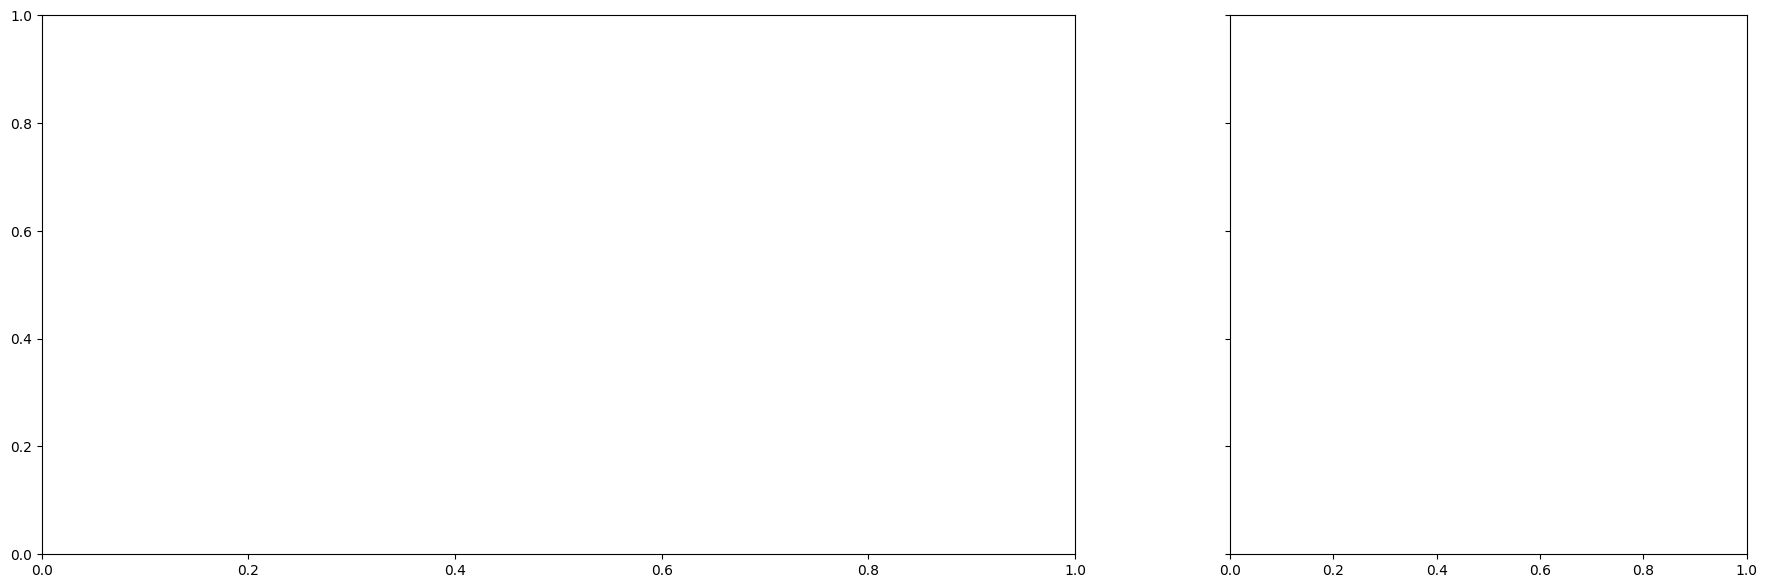

In [36]:
# Side-by-side plots: Full range (left) & zoom on 2022-2025 (right)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(22, 7), sharey=True, gridspec_kw={'width_ratios': [2, 1]})

models = sorted(df_gap_agg["model"].unique())
colors = get_model_color_map(models)

# Determine all years over the full set of explicit_best_years
all_years = sorted(df_gap_agg["explicit_best_year"].dropna().unique())
# Set up zoomed years (2022-2025, or fallback as before)
zoom_years = [y for y in all_years if 2020 <= float(y) <= 2025]
if not zoom_years:
    zoom_years = [y for y in all_years if float(y) >= 2022][:4]

# Plot: one line per model — x = explicit_best_year, y = mean year_diff in that bucket (Full)
for m in models:
    sub = df_gap_agg[df_gap_agg["model"] == m].sort_values("explicit_best_year")
    if sub.empty:
        continue
    sub_full = sub.set_index("explicit_best_year").reindex(all_years)
    ax.plot(
        all_years,
        sub_full["mean_year_diff"],
        marker="o",
        markersize=5,
        linewidth=2,
        color=colors[m],
        label=m,
        alpha=0.85,
    )
# Full plot decoration
ax.axhline(0, color="gray", linestyle="--", linewidth=1, alpha=0.6)
ax.set_xlabel("Best explicit event year (per question)", fontsize=14, fontweight="bold")
ax.set_ylabel("Mean (best explicit year − best relative year)", fontsize=14, fontweight="bold")
ax.set_title(
    "All Years",
    fontsize=14,
    fontweight="bold",
)
ax.grid(axis="y", alpha=0.3)
# No legend on the first plot now
ax.set_xticks(all_years)
ax.set_xticklabels([str(int(y)) if float(y).is_integer() else str(y) for y in all_years], rotation=45)

# Plot: one line per model — x = explicit_best_year, y = mean year_diff in that bucket (Zoom)
for m in models:
    sub = df_gap_agg[df_gap_agg["model"] == m].sort_values("explicit_best_year")
    if sub.empty:
        continue
    sub_zoom = sub.set_index("explicit_best_year").reindex(zoom_years)
    ax2.plot(
        zoom_years,
        sub_zoom["mean_year_diff"],
        marker="o",
        markersize=5,
        linewidth=2,
        color=colors[m],
        label=m,
        alpha=0.85,
    )
ax2.axhline(0, color="gray", linestyle="--", linewidth=1, alpha=0.6)
ax2.set_xlabel("Best explicit event year (per question)", fontsize=13, fontweight="bold")
# No ylabel on ax2 since it's shared with ax
ax2.set_title(
    "Zoom: 2022–2025",
    fontsize=14,
    fontweight="bold",
)
ax2.grid(axis="y", alpha=0.3)
# Tight legend on the zoomed subplot (ax2)
# place outside top-right but close, with a small frame and less spacing
ax2.legend(
    bbox_to_anchor=(1.01, 1),
    borderaxespad=0.5,
    borderpad=0.5,
    loc="upper left",
    fontsize=9,
    title="Model",
    title_fontsize=10,
    labelspacing=0.25,
    handlelength=1.2,
    handletextpad=0.6,
    frameon=True,
    framealpha=0.92,
    fancybox=True,
    edgecolor="gray",
)
ax2.set_xticks(zoom_years)
ax2.set_xticklabels([str(int(y)) if float(y).is_integer() else str(y) for y in zoom_years], rotation=45)

fig.suptitle(
    "",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()